# AMOS — Analytic Margin-Outlier Sensitivity
### Zero-shot prediction of post-training-quantization (PTQ) reliability from one FP32 forward pass

This notebook is the complete, resumable experiment behind the paper:

1. **Model zoo** — 16 pretrained CIFAR-100 CNNs (4 families, no training needed) or an ImageNet `timm` zoo.
2. **Proxies** — AMOS (+ ablation variants) and baselines: NASWOT, SynFlow, GradNorm, HAWQ-style Hessian sensitivity, weight-range ratio (CLE), weight kurtosis, #params, FP32 accuracy.
3. **Ground truth** — a self-contained fake-quantization PTQ simulator (BN folding, per-channel weights with MSE clipping, calibrated per-tensor activations) run for W8A8 (control), W4A8, W4A4 with several calibration subsets.
4. **Evaluation** — Spearman/Kendall with bootstrap CIs, family-adjusted correlation, leave-one-out *selection regret*, cost/speed comparison, probe-size / probe-type / seed-stability ablations.
5. **Paper assets** — 9 figures (PNG + PDF at 300 dpi) and CSV/LaTeX tables, saved to Drive and zipped.

**How to run:** Runtime → GPU (T4 is fine). Set `MODE = "pilot"` first (~10–15 min), check the sanity prints, then `MODE = "full"`. Every unit of work is checkpointed to Drive, so a disconnect only costs you the current unit — re-run all cells and it resumes.

> **Read this before trusting any number.** The draft proposal states targets (ρ > 0.80, 1000× speed-up). They are hypotheses. The last cells print an honest *claims check*; report whatever it says.

In [ ]:
# CELL 1 — Setup, configuration, checkpointing
!pip -q install timm scipy pandas matplotlib seaborn tqdm

import os, re, json, time, math, copy, random, warnings
from functools import reduce, partial
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from tqdm.auto import tqdm
from scipy import stats
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")

# ------------------------------ USER CONFIG ------------------------------
MODE  = "full"      # "pilot" (small, fast sanity run)  or  "full"
TRACK = "imagenet"   # "cifar100": 16 pretrained CIFAR-100 CNNs  |  "imagenet": 30 pretrained timm models, data AUTO-DOWNLOADED (see below)
IMAGENET_SOURCE = "v2"                       # "v2": ImageNetV2 matched-frequency, 10,000 images / 1000 classes, public, auto-download (~1.2 GB, no login)
                                             # "folder": your own ImageNet-1k val folder (IMAGENET_VAL_DIR below)
IMAGENET_VAL_DIR = "/content/imagenet_val"   # only for IMAGENET_SOURCE="folder": <dir>/<wnid>/*.JPEG
QUANT_CONFIGS = None                         # None = auto. CIFAR: W8A8,W4A8,W4A4 | ImageNet: W8A8,W4A8,W6A6,W4A4   (weight bits, activation bits)
ACT_RANGE = "percentile"                     # activation range estimator: "percentile" (99.99) or "minmax"
KEEP_FIRST_LAST_8BIT = True                  # first/last layer kept at 8 bit (standard PTQ convention)
SEED = 0
QUALITY_GATE = True                          # exclude models whose ground truth is internally inconsistent (a quantised accuracy > FP32 + 2 pp, or FP32 < 20%)
# --------------------------------------------------------------------------

PRESET = {
    "pilot": dict(n_eval=2000,  n_calib=128, n_trials=2, n_probe_seeds=3,  probe_sizes=[8, 32, 128]),
    "full":  dict(n_eval=10000, n_calib=128, n_trials=3, n_probe_seeds=10, probe_sizes=[8, 16, 32, 64, 128]),
}[MODE]
if TRACK == "imagenet":
    PRESET = dict(PRESET, n_eval=2000 if MODE == "pilot" else 5000)      # ImageNetV2 has 10,000 images: 1000 go to the probe/calibration pool
if QUANT_CONFIGS is None:
    QUANT_CONFIGS = [(8, 8), (4, 8), (4, 4)] if TRACK == "cifar100" else [(8, 8), (4, 8), (6, 6), (4, 4)]

try:
    from google.colab import drive
    drive.mount("/content/drive")
    WORKDIR = "/content/drive/MyDrive/amos_project"
except Exception:
    WORKDIR = "./amos_project"
DATA_ROOT = "/content/data" if os.path.isdir("/content") else "./data"
SFX = "" if ACT_RANGE == "percentile" else f"_{ACT_RANGE}"   # separate checkpoints per activation-range estimator
FIGDIR = f"{WORKDIR}/figs_{TRACK}_{MODE}{SFX}"
os.makedirs(FIGDIR, exist_ok=True)
CKPT_PATH = f"{WORKDIR}/ckpt_{TRACK}_{MODE}{SFX}.json"

class Ckpt:
    # tiny JSON key-value store, atomically rewritten after every put() -> safe resume
    def __init__(self, path):
        self.path = path
        self.d = json.load(open(path)) if os.path.exists(path) else {}
    def has(self, k): return k in self.d
    def get(self, k): return self.d[k]
    def put(self, k, v):
        self.d[k] = v
        tmp = self.path + ".tmp"
        with open(tmp, "w") as f: json.dump(self.d, f)
        os.replace(tmp, self.path)
CK = Ckpt(CKPT_PATH)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
def sync_time():
    if device == "cuda": torch.cuda.synchronize()
    return time.perf_counter()

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
def savefig(name):
    plt.savefig(f"{FIGDIR}/{name}.png", bbox_inches="tight"); plt.savefig(f"{FIGDIR}/{name}.pdf", bbox_inches="tight")
    plt.show()

print(f"device={device} | MODE={MODE} | TRACK={TRACK} | checkpoint={CKPT_PATH} ({len(CK.d)} units already done)")
print("PRESET:", PRESET)

Mounted at /content/drive
device=cuda | MODE=full | TRACK=imagenet | checkpoint=/content/drive/MyDrive/amos_project/ckpt_imagenet_full.json (1440 units already done)
PRESET: {'n_eval': 5000, 'n_calib': 128, 'n_trials': 3, 'n_probe_seeds': 10, 'probe_sizes': [8, 16, 32, 64, 128]}


## 1. Data and model zoo
CIFAR-100 track: the zoo comes from `chenyaofo/pytorch-cifar-models` (`torch.hub`), so all models are *already trained on CIFAR-100*; nothing is fine-tuned. (RepVGG entries are skipped on purpose: their multi-branch re-parameterisation breaks the generic BN-folding used below.)

Probe images (for the proxies) and calibration images (for PTQ) are drawn from the **training split** (CIFAR) / a held-out 1000-image pool (ImageNet). Evaluation uses a fixed random subset of the **test split**. Probe images are used *without labels* by AMOS.

In [ ]:
# CELL 2 — Dataset (kept on GPU as uint8) + per-model normalisation
FAMILIES = {"cifar100": ["resnet", "vgg", "mobilenetv2", "shufflenetv2"],
            "imagenet": ["resnet", "vgg", "mobilenetv2", "mobilenetv3", "efficientnet", "mnasnet", "ghostnet", "regnet", "convnext", "vit"]}[TRACK]
FAM_ALIAS = {"deit": "vit"}
def family_of(name):
    for k, v in FAM_ALIAS.items():
        if name.startswith(k): return v
    for f in FAMILIES:
        if name.startswith(f): return f
    return "other"
PAL = dict(zip(FAMILIES + ["other"], sns.color_palette("Set2", len(FAMILIES) + 1)))

import urllib.request, shutil
from PIL import Image
_BICUBIC = getattr(Image, "Resampling", Image).BICUBIC

def _decode_224(im):
    # resize shorter side to 256 (bicubic) + center-crop 224 -> uint8 CHW tensor
    w, h = im.size
    nw, nh = (256, max(256, round(h * 256 / w))) if w <= h else (max(256, round(w * 256 / h)), 256)
    im = im.convert("RGB").resize((nw, nh), _BICUBIC); l, t = (nw - 224) // 2, (nh - 224) // 2
    return torch.from_numpy(np.asarray(im.crop((l, t, l + 224, t + 224))).copy()).permute(2, 0, 1)

class _ImgDS(torch.utils.data.Dataset):
    def __init__(self, items): self.items = items
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        p, y = self.items[i]
        with Image.open(p) as im: return _decode_224(im), y

def _download(url, dst):
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req) as r, open(dst, "wb") as f: shutil.copyfileobj(r, f, 1 << 20)

def list_imagenet_items():
    if IMAGENET_SOURCE == "v2":
        root = f"{DATA_ROOT}/imagenetv2-matched-frequency-format-val"       # folder name = ImageNet-1k class index 0..999
        if not os.path.isdir(root):
            os.makedirs(DATA_ROOT, exist_ok=True); tar_path = f"{DATA_ROOT}/imagenetv2-matched-frequency.tar.gz"; ok = False
            for u in ["https://huggingface.co/datasets/vaishaal/ImageNetV2/resolve/main/imagenetv2-matched-frequency.tar.gz",
                      "https://s3-us-west-2.amazonaws.com/imagenetv2public/imagenetv2-matched-frequency.tar.gz"]:
                try:
                    print("downloading", u, "(~1.2 GB)"); _download(u, tar_path); ok = True; break
                except Exception as e: print("   failed:", str(e)[:100])
            if not ok: raise RuntimeError("Could not download ImageNetV2. Check internet access, or set IMAGENET_SOURCE='folder' and point IMAGENET_VAL_DIR to an ImageNet val folder.")
            import tarfile; print("extracting ..."); tarfile.open(tar_path).extractall(DATA_ROOT); os.remove(tar_path)
        return [(f"{root}/{c}/{f}", int(c)) for c in sorted(os.listdir(root), key=int) for f in sorted(os.listdir(f"{root}/{c}"))]
    classes = sorted(d for d in os.listdir(IMAGENET_VAL_DIR) if os.path.isdir(os.path.join(IMAGENET_VAL_DIR, d)))
    if len(classes) != 1000: print(f"WARNING: found {len(classes)} class folders (timm ImageNet-1k checkpoints expect 1000 WordNet-id folders)")
    return [(f"{IMAGENET_VAL_DIR}/{c}/{f}", i) for i, c in enumerate(classes) for f in sorted(os.listdir(f"{IMAGENET_VAL_DIR}/{c}"))]

def load_imagenet():
    cache = f"{WORKDIR}/imagenet_{IMAGENET_SOURCE}_n{PRESET['n_eval']}.pt"       # decoded tensors cached on Drive -> instant on re-runs
    if os.path.exists(cache):
        print("loading cached ImageNet tensors:", cache); return torch.load(cache)
    items = list_imagenet_items(); print(f"{len(items)} images found")
    rng = np.random.default_rng(123); by_cls = {}
    for p, y in items: by_cls.setdefault(y, []).append((p, y))
    pool, rest = [], []
    for y in sorted(by_cls):
        L = by_cls[y]; rng.shuffle(L); pool.append(L[0]); rest += L[1:]             # 1 probe/calibration image per class, never used for evaluation
    rng.shuffle(rest); ev = rest[: PRESET["n_eval"]]
    dl = torch.utils.data.DataLoader(_ImgDS(pool + ev), batch_size=100, num_workers=2)
    xs, ys = [], []
    for x, y in tqdm(dl, desc="decoding ImageNet images"): xs.append(x); ys.append(y)
    X, Y = torch.cat(xs), torch.cat(ys); n = len(pool)
    d = dict(pool_x=X[:n], pool_y=Y[:n], eval_x=X[n:], eval_y=Y[n:])
    try: torch.save(d, cache)
    except Exception as e: print("cache save failed:", str(e)[:80])
    return d

def load_data():
    g = torch.Generator().manual_seed(123)
    if TRACK == "cifar100":
        tr = torchvision.datasets.CIFAR100(DATA_ROOT, train=True, download=True)
        te = torchvision.datasets.CIFAR100(DATA_ROOT, train=False, download=True)
        t = lambda a: torch.from_numpy(a).permute(0, 3, 1, 2).contiguous()
        Xtr, Ytr, Xte, Yte = t(tr.data), torch.tensor(tr.targets), t(te.data), torch.tensor(te.targets)
        perm = torch.randperm(len(Xte), generator=g)[:PRESET["n_eval"]]
        d = dict(pool_x=Xtr, pool_y=Ytr, eval_x=Xte[perm], eval_y=Yte[perm])
    else:
        d = load_imagenet()
    return {k: v.to(device) for k, v in d.items()}
DATA = load_data()
print({k: tuple(v.shape) for k, v in DATA.items()})

def norm_cfg_for(model):
    if TRACK == "cifar100":
        return (0.5071, 0.4865, 0.4409), (0.2673, 0.2564, 0.2762)
    import timm
    cfg = timm.data.resolve_data_config({}, model=model)
    return tuple(cfg["mean"]), tuple(cfg["std"])

def prep(x_u8, model):
    mean, std = model.norm_cfg
    x = x_u8.float() / 255.0
    m = torch.tensor(mean, device=device).view(1, 3, 1, 1); s = torch.tensor(std, device=device).view(1, 3, 1, 1)
    return (x - m) / s

@torch.no_grad()
def evaluate(model, bs=None):
    bs = bs or (500 if TRACK == "cifar100" else 100)
    model.eval(); X, Y = DATA["eval_x"], DATA["eval_y"]; correct = 0
    for i in range(0, len(X), bs):
        correct += (model(prep(X[i:i + bs], model)).argmax(1) == Y[i:i + bs]).sum().item()
    return 100.0 * correct / len(X)

loading cached ImageNet tensors: /content/drive/MyDrive/amos_project/imagenet_v2_n5000.pt
{'pool_x': (1000, 3, 224, 224), 'pool_y': (1000,), 'eval_x': (5000, 3, 224, 224), 'eval_y': (5000,)}


In [ ]:
# CELL 3 — Model zoo
CIFAR_ALL = ["resnet20", "resnet32", "resnet44", "resnet56",
             "vgg11_bn", "vgg13_bn", "vgg16_bn", "vgg19_bn",
             "mobilenetv2_x0_5", "mobilenetv2_x0_75", "mobilenetv2_x1_0", "mobilenetv2_x1_4",
             "shufflenetv2_x0_5", "shufflenetv2_x1_0", "shufflenetv2_x1_5", "shufflenetv2_x2_0"]
CIFAR_PILOT = ["resnet20", "resnet56", "vgg11_bn", "vgg16_bn", "mobilenetv2_x0_5", "mobilenetv2_x1_0",
               "shufflenetv2_x0_5", "shufflenetv2_x1_5"]
IMNET_SPECS = [  # (timm model name, preferred pretrained-weights tag).  If a tag does not exist in your timm version the default weights are used (recorded in the table as 'recipe')
    ("resnet18", "tv_in1k"), ("resnet34", "tv_in1k"), ("resnet50", "tv_in1k"), ("resnet101", "tv_in1k"),
    ("vgg11_bn", "tv_in1k"), ("vgg16_bn", "tv_in1k"),
    ("mobilenetv2_050", "lamb_in1k"), ("mobilenetv2_100", "ra_in1k"), ("mobilenetv2_140", "ra_in1k"),
    ("mobilenetv3_small_100", "lamb_in1k"), ("mobilenetv3_large_100", "ra_in1k"),
    ("efficientnet_b0", "ra_in1k"), ("efficientnet_b1", "ft_in1k"), ("efficientnet_b2", "ra_in1k"), ("efficientnet_lite0", "ra_in1k"),
    ("mnasnet_100", "rmsp_in1k"), ("ghostnet_100", "in1k"),
    ("regnetx_004", "pycls_in1k"), ("regnetx_008", "pycls_in1k"), ("regnetx_016", "pycls_in1k"), ("regnety_008", "pycls_in1k"),
    ("convnext_atto", "d2_in1k"), ("convnext_femto", "d1_in1k"), ("convnext_pico", "d1_in1k"), ("convnext_nano", "d1h_in1k"), ("convnext_tiny", "in12k_ft_in1k"),
    ("vit_tiny_patch16_224", "augreg_in21k_ft_in1k"), ("vit_small_patch16_224", "augreg_in21k_ft_in1k"),
    ("deit_tiny_patch16_224", "fb_in1k"), ("deit_small_patch16_224", "fb_in1k")]
IMNET_TAG = dict(IMNET_SPECS)
IMNET_ALL = [n for n, _ in IMNET_SPECS]
IMNET_PILOT = ["resnet18", "resnet50", "vgg11_bn", "mobilenetv2_100", "mobilenetv3_large_100", "efficientnet_b0",
               "regnetx_008", "ghostnet_100", "convnext_nano", "vit_tiny_patch16_224", "deit_small_patch16_224"]
NAMES = {("cifar100", "pilot"): CIFAR_PILOT, ("cifar100", "full"): CIFAR_ALL,
         ("imagenet", "pilot"): IMNET_PILOT, ("imagenet", "full"): IMNET_ALL}[(TRACK, MODE)]

def load_model(name):
    if TRACK == "cifar100":
        m = torch.hub.load("chenyaofo/pytorch-cifar-models", f"cifar100_{name}", pretrained=True, trust_repo=True, verbose=False)
    else:
        import timm
        try: m = timm.create_model(f"{name}.{IMNET_TAG[name]}", pretrained=True); recipe = IMNET_TAG[name]
        except Exception: m = timm.create_model(name, pretrained=True); recipe = "default"
    m = m.eval().to(device)
    m.recipe = recipe if TRACK == "imagenet" else "-"
    m.norm_cfg = norm_cfg_for(m)
    return m

ZOO = {}
for n in NAMES:
    try: ZOO[n] = load_model(n)
    except Exception as e: print(f"  !! skipped {n}: {str(e)[:120]}")
print(f"{len(ZOO)} models loaded:", list(ZOO))

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 22.9MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

30 models loaded: ['resnet18', 'resnet34', 'resnet50', 'resnet101', 'vgg11_bn', 'vgg16_bn', 'mobilenetv2_050', 'mobilenetv2_100', 'mobilenetv2_140', 'mobilenetv3_small_100', 'mobilenetv3_large_100', 'efficientnet_b0', 'efficientnet_b1', 'efficientnet_b2', 'efficientnet_lite0', 'mnasnet_100', 'ghostnet_100', 'regnetx_004', 'regnetx_008', 'regnetx_016', 'regnety_008', 'convnext_atto', 'convnext_femto', 'convnext_pico', 'convnext_nano', 'convnext_tiny', 'vit_tiny_patch16_224', 'vit_small_patch16_224', 'deit_tiny_patch16_224', 'deit_small_patch16_224']


## 2. BatchNorm folding + PTQ simulator (ground truth)
**Protocol (document this in the paper):** BN folded into the preceding conv → per-output-channel symmetric weight quantisation with MSE-optimal clipping search (for < 8 bit) → per-tensor asymmetric activation quantisation at the *input of every conv/linear layer*, ranges estimated on a calibration subset (99.99-percentile by default) → first and last layer at 8 bit. Attention matmuls / softmax / LayerNorm stay FP32 (limitation for ViT, state it).

Calibration trials re-draw the 128 calibration images with different seeds; their spread is the *calibration-induced* variability from the original proposal.

In [ ]:
# CELL 4 — module helpers, BN folding (with numerical self-check), fake-quant PTQ
def get_module(model, path): return reduce(getattr, path.split("."), model)
def set_module(model, path, new):
    parts = path.split(".")
    parent = reduce(getattr, parts[:-1], model) if len(parts) > 1 else model
    setattr(parent, parts[-1], new)
def qlayer_names(model): return [n for n, m in model.named_modules() if isinstance(m, (nn.Conv2d, nn.Linear))]

@torch.no_grad()
def fold_bn(model, x_check):
    # fold Conv2d -> BatchNorm2d pairs that are adjacent in module registration order; verify equivalence
    m = copy.deepcopy(model).eval()
    mods = list(m.named_modules()); fused = 0
    for i in range(len(mods) - 1):
        (n1, a), (n2, b) = mods[i], mods[i + 1]
        if isinstance(a, nn.Conv2d) and isinstance(b, nn.BatchNorm2d) and a.out_channels == b.num_features:
            set_module(m, n1, torch.nn.utils.fusion.fuse_conv_bn_eval(a, b))
            act = getattr(b, "act", None)                     # timm BatchNormAct2d keeps its activation
            set_module(m, n2, act if isinstance(act, nn.Module) else nn.Identity())
            fused += 1
    ref, out = model(x_check), m(x_check)
    err = (ref - out).abs().max().item(); ok = err <= 1e-3 * max(1.0, ref.abs().max().item())
    return (m if ok else copy.deepcopy(model).eval()), fused, err, ok

def quant_w(w, bits, search=True):
    # per-output-channel symmetric quantisation; MSE clipping search when bits < 8
    qmax = 2 ** (bits - 1) - 1
    wf = w.detach().reshape(w.shape[0], -1).float()
    amax = wf.abs().amax(1, keepdim=True).clamp_min(1e-8)
    ratios = torch.linspace(0.4, 1.0, 13, device=w.device) if (search and bits < 8) else torch.ones(1, device=w.device)
    best, best_err = None, None
    for r in ratios:
        s = amax * r / qmax
        q = torch.clamp(torch.round(wf / s), -qmax - 1, qmax) * s
        err = (q - wf).pow(2).sum(1, keepdim=True)
        if best is None: best, best_err = q, err
        else:
            better = err < best_err
            best, best_err = torch.where(better, q, best), torch.where(better, err, best_err)
    return best.reshape(w.shape).to(w.dtype)

def quant_act(x, lo, hi, bits):
    n = 2 ** bits - 1
    s = ((hi - lo) / n).clamp_min(1e-8); zp = torch.round(-lo / s)
    return (torch.clamp(torch.round(x / s) + zp, 0, n) - zp) * s

class QLayer(nn.Module):
    # wraps a Conv2d/Linear: modes "fp" -> "calib" (observe input ranges) -> "quant" (fake-quant inputs + weights)
    def __init__(self, layer, wbits, abits):
        super().__init__()
        self.layer, self.wbits, self.abits = layer, wbits, abits
        self.register_buffer("w_fp", layer.weight.detach().clone())
        self.mode, self.lo, self.hi, self._lo, self._hi = "fp", None, None, [], []
    @torch.no_grad()
    def observe(self, x):
        xf = x.detach().float().flatten()
        if ACT_RANGE == "minmax":
            lo, hi = xf.min(), xf.max()
        else:
            if xf.numel() > 2_000_000: xf = xf[torch.randint(0, xf.numel(), (2_000_000,), device=xf.device)]
            q = torch.quantile(xf, torch.tensor([1e-4, 1 - 1e-4], device=xf.device)); lo, hi = q[0], q[1]
        self._lo.append(lo); self._hi.append(hi)
    @torch.no_grad()
    def finalize(self):
        L, H = torch.stack(self._lo), torch.stack(self._hi)
        lo, hi = (L.min(), H.max()) if ACT_RANGE == "minmax" else (L.mean(), H.mean())
        self.lo, self.hi = torch.minimum(lo, torch.zeros_like(lo)), torch.maximum(hi, torch.zeros_like(hi))
        self.layer.weight.data.copy_(quant_w(self.w_fp, self.wbits)); self.mode = "quant"
    def forward(self, x):
        if self.mode == "calib": self.observe(x)
        elif self.mode == "quant": x = quant_act(x, self.lo, self.hi, self.abits)
        return self.layer(x)

def build_ptq(folded, wbits, abits):
    qm = copy.deepcopy(folded); names = qlayer_names(qm)
    for i, n in enumerate(names):
        edge = KEEP_FIRST_LAST_8BIT and i in (0, len(names) - 1)
        set_module(qm, n, QLayer(get_module(qm, n), 8 if edge else wbits, 8 if edge else abits))
    return qm.eval()

def run_ptq(folded, wbits, abits, seed):
    # returns (top-1 accuracy of the quantised model, wall-clock seconds for calibrate+quantise+evaluate)
    t0 = sync_time()
    qm = build_ptq(folded, wbits, abits)
    g = torch.Generator().manual_seed(seed); n = PRESET["n_calib"]
    cx = DATA["pool_x"][torch.randperm(len(DATA["pool_x"]), generator=g)[:n].to(device)]
    QL = [m for m in qm.modules() if isinstance(m, QLayer)]
    for q in QL: q.mode = "calib"
    with torch.no_grad():
        for i in range(0, n, 64): qm(prep(cx[i:i + 64], qm))
    for q in QL: q.finalize()
    acc = evaluate(qm); dt = sync_time() - t0
    del qm; torch.cuda.empty_cache() if device == "cuda" else None
    return acc, dt

# ---- fold every model and run the sanity checks
FOLDED = {}
for n, m in ZOO.items():
    x0 = prep(DATA["pool_x"][:16], m)
    with torch.no_grad(): fm, nf, err, ok = fold_bn(m, x0)
    FOLDED[n] = fm
    print(f"{n:22s} folded {nf:3d} BN | max|diff|={err:.2e} | {'OK' if ok else 'FOLD FAILED -> BN left unfolded'}")

resnet18               folded  20 BN | max|diff|=4.58e-05 | OK
resnet34               folded  36 BN | max|diff|=4.01e-05 | OK
resnet50               folded  53 BN | max|diff|=2.67e-05 | OK
resnet101              folded 104 BN | max|diff|=2.86e-05 | OK
vgg11_bn               folded   8 BN | max|diff|=5.58e-05 | OK
vgg16_bn               folded  13 BN | max|diff|=7.06e-05 | OK
mobilenetv2_050        folded  52 BN | max|diff|=3.24e-05 | OK
mobilenetv2_100        folded  52 BN | max|diff|=1.34e-05 | OK
mobilenetv2_140        folded  52 BN | max|diff|=1.43e-05 | OK
mobilenetv3_small_100  folded  34 BN | max|diff|=1.53e-05 | OK
mobilenetv3_large_100  folded  46 BN | max|diff|=8.94e-06 | OK
efficientnet_b0        folded  49 BN | max|diff|=1.43e-05 | OK
efficientnet_b1        folded  69 BN | max|diff|=8.23e-06 | OK
efficientnet_b2        folded  69 BN | max|diff|=8.58e-06 | OK
efficientnet_lite0     folded  49 BN | max|diff|=1.48e-05 | OK
mnasnet_100            folded  52 BN | max|diff|=1.00e-

## 3. The AMOS proxy and baselines
**AMOS(M) = κ̄ / V_d** from a single FP32 forward pass over *N = 32 unlabeled* images.

* κ̄ — mean excess-free (non-excess) kurtosis of the activation tensor **entering** each conv/linear layer (that is exactly what the A-bit quantiser sees). First and last layers are excluded, mirroring the 8-bit convention of the simulator. The draft hooked layer *outputs* (pre-BN for convs); that variant is kept as `AMOS_out` for the ablation.
* V_d — mean normalised top-1/top-2 logit gap `(z₁−z₂)/‖z‖₂`.
* The draft leaves the layer weights `w_l` undefined; the ablation compares uniform mean (default), geometric mean, median, max, param-weighted and depth-weighted aggregation.

Baselines: **NASWOT**, **SynFlow** (BN in eval mode — an approximation for pretrained nets), **GradNorm**, a **HAWQ-style** Hessian-trace × 4-bit-weight-perturbation score (needs backward/HVP — the "expensive but principled" reference), **weight range ratio** (cross-channel range dispersion after BN folding, the data-free-quantization motivation) and **weight kurtosis** (KURE-inspired).

In [ ]:
# CELL 5 — proxies
def kurtosis(x):
    x = x.detach().float().flatten(); m = x.mean(); s = x.std(unbiased=False) + 1e-8
    return ((x - m) / s).pow(4).mean().item()

def outlier_ratio(x):
    # abs-max / 99.9th percentile of |x| : how much a min-max range over-covers the bulk
    a = x.detach().float().abs().flatten(); mx = a.max()
    if a.numel() > 2_000_000: a = a[torch.randint(0, a.numel(), (2_000_000,), device=a.device)]
    return (mx / (torch.quantile(a, 0.999) + 1e-8)).item()

@torch.no_grad()
def layer_stats(model, x):
    names = qlayer_names(model); rec = {n: [] for n in names}; hooks = []
    def mk(n):
        def hook(mod, inp, out):
            rec[n].append(dict(k_in=kurtosis(inp[0]), k_out=kurtosis(out), omega=outlier_ratio(inp[0]), nparams=mod.weight.numel()))
        return hook
    for n in names: hooks.append(get_module(model, n).register_forward_hook(mk(n)))
    model.eval(); z = model(x)
    for h in hooks: h.remove()
    ls = [{k: float(np.mean([r[k] for r in rec[n]])) for k in rec[n][0]} for n in names if rec[n]]
    return ls, z

def margin_stats(z):
    z = z.detach().float(); t = torch.topk(z, 2, dim=1).values; gap = t[:, 0] - t[:, 1]
    gn = gap / (z.norm(dim=1) + 1e-6); tp = torch.topk(F.softmax(z, 1), 2, dim=1).values
    return dict(vd=gn.mean().item(), gap=gap.mean().item(), pgap=(tp[:, 0] - tp[:, 1]).mean().item(), gaps_norm=gn.cpu().tolist())

def agg(v, ls, how):
    v = np.asarray(v, float); L = len(v)
    if how == "mean":   return float(v.mean())
    if how == "geo":    return float(np.exp(np.log(np.maximum(v, 1e-8)).mean()))
    if how == "median": return float(np.median(v))
    if how == "max":    return float(v.max())
    if how == "param":  w = np.array([l["nparams"] for l in ls], float); return float((w * v).sum() / w.sum())
    if how == "depth":  w = np.arange(1, L + 1, dtype=float); return float((w * v).sum() / w.sum())

def amos_variants(ls, ms):
    inner = ls[1:-1] if len(ls) > 2 else ls          # drop first/last layer (kept at 8 bit in the PTQ protocol)
    kin, kout, om = [l["k_in"] for l in inner], [l["k_out"] for l in inner], [l["omega"] for l in inner]
    vd = ms["vd"] + 1e-6
    out = {f"AMOS[{h}]": agg(kin, inner, h) / vd for h in ["mean", "geo", "median", "max", "param", "depth"]}
    out["AMOS"] = out["AMOS[mean]"]
    out["AMOS_out"] = agg(kout, inner, "mean") / vd
    out["AMOS_omega"] = agg(om, inner, "mean") / vd
    out["AMOS_pgap"] = agg(kin, inner, "mean") / (ms["pgap"] + 1e-6)
    out["kurt_only"] = agg(kin, inner, "mean"); out["omega_only"] = agg(om, inner, "mean"); out["inv_margin"] = 1.0 / vd
    return out

def get_probe(model, seed, n, kind="real"):
    g = torch.Generator().manual_seed(10_000 + seed)
    idx = torch.randperm(len(DATA["pool_x"]), generator=g)[:n].to(device)
    x = prep(DATA["pool_x"][idx], model)
    if kind == "gauss": x = torch.randn_like(x)        # what the draft code used (torch.randn) -> expected to be uninformative
    return x, DATA["pool_y"][idx]

def amos_only(model, seed, n, kind="real"):
    x, _ = get_probe(model, seed, n, kind)
    ls, z = layer_stats(model, x); return amos_variants(ls, margin_stats(z))["AMOS"]

# ---------------- baselines ----------------
ACTS = (nn.ReLU, nn.ReLU6, nn.SiLU, nn.GELU, nn.Hardswish)
def naswot(model, x):
    N = x.shape[0]; K = torch.zeros(N, N, device=x.device, dtype=torch.float64); hooks = []
    def hook(mod, inp, out):
        nonlocal K
        c = (out.detach().reshape(N, -1) > 0).double(); K = K + c @ c.T + (1 - c) @ (1 - c).T
    for m in model.modules():
        if isinstance(m, ACTS): hooks.append(m.register_forward_hook(hook))
    with torch.no_grad(): model.eval(); model(x)
    for h in hooks: h.remove()
    return torch.linalg.slogdet(K)[1].item() if hooks else float("nan")

def _no_inplace(m):
    for mod in m.modules():
        if hasattr(mod, "inplace"): mod.inplace = False
    return m

def synflow(model, shape):
    m = _no_inplace(copy.deepcopy(model).double().eval())
    with torch.no_grad():
        for p in list(m.parameters()) + list(m.buffers()):
            if p.dtype.is_floating_point: p.abs_()
    m.zero_grad(); out = m(torch.ones((1,) + tuple(shape[1:]), dtype=torch.float64, device=device)); out.sum().backward()
    s = sum((mod.weight.grad * mod.weight).sum().item() for mod in m.modules()
            if isinstance(mod, (nn.Conv2d, nn.Linear)) and mod.weight.grad is not None)
    return math.log10(s) if (s > 0 and math.isfinite(s)) else float("nan")

def grad_norm(model, x, y):
    m = _no_inplace(copy.deepcopy(model).eval()); m.zero_grad()
    F.cross_entropy(m(x), y).backward()
    return math.sqrt(sum((p.grad ** 2).sum().item() for p in m.parameters() if p.grad is not None))

def hawq_score(model, x, y, wbits=4, n_iter=8):
    # HAWQ-style: sum_l  Tr(H_l)/n_l * ||Q(W_l) - W_l||^2   (Hutchinson trace estimator)
    m = _no_inplace(copy.deepcopy(model).eval())
    params = [get_module(m, n).weight for n in qlayer_names(m)]
    grads = torch.autograd.grad(F.cross_entropy(m(x), y), params, create_graph=True, allow_unused=True)
    pairs = [(p, g) for p, g in zip(params, grads) if g is not None]
    tr = np.zeros(len(pairs))
    for _ in range(n_iter):
        vs = [(torch.randint_like(p, 0, 2) * 2 - 1).float() for p, _ in pairs]
        Hv = torch.autograd.grad([g for _, g in pairs], [p for p, _ in pairs], grad_outputs=vs, retain_graph=True, allow_unused=True)
        tr += np.array([0.0 if h is None else (h * v).sum().item() for h, v in zip(Hv, vs)]) / n_iter
    return float(sum(t / p.numel() * (quant_w(p.detach(), wbits) - p.detach()).pow(2).sum().item() for t, (p, _) in zip(tr, pairs)))

def weight_stats(folded):
    names = qlayer_names(folded); names = names[1:-1] if len(names) > 2 else names
    ks, rr = [], []
    for n in names:
        w = get_module(folded, n).weight.detach().float(); am = w.reshape(w.shape[0], -1).abs().amax(1)
        ks.append(kurtosis(w)); rr.append((am.max() / (am.median() + 1e-8)).item())
    return dict(w_kurt=float(np.mean(ks)), w_range=float(np.mean(rr)))

def timed(fn, *a):
    try:
        t0 = sync_time(); v = fn(*a); return float(v), sync_time() - t0
    except Exception as e:
        print(f"     (baseline {getattr(fn, '__name__', 'fn')} failed: {str(e)[:80]})")
        if device == "cuda": torch.cuda.empty_cache()
        return float("nan"), float("nan")

In [ ]:
# CELL 6 — compute all proxies for all models (checkpointed). AMOS runs on every probe seed; baselines on the first 3 seeds, HAWQ on seed 0.
for name in tqdm(list(ZOO), desc="proxies"):
    model = ZOO[name]
    with torch.no_grad(): model(get_probe(model, 0, 8)[0])                       # GPU warm-up so timings are fair
    if not CK.has(f"static|{name}"):
        CK.put(f"static|{name}", weight_stats(FOLDED[name]))
    for s in range(PRESET["n_probe_seeds"]):
        key = f"proxy|{name}|real|n32|s{s}"
        if CK.has(key): continue
        x, y = get_probe(model, s, 32)
        xb, yb = (x, y) if TRACK == "cifar100" else (x[:16], y[:16])        # gradient / Hessian baselines on 16 images at ImageNet resolution (memory)
        t0 = sync_time(); ls, z = layer_stats(model, x); ms = margin_stats(z); am = amos_variants(ls, ms); t_amos = sync_time() - t0
        rec = dict(amos=am, t_amos=t_amos, vd=ms["vd"])
        if s == 0: rec["layers"], rec["gaps"] = ls, ms["gaps_norm"]
        if s < 3:
            rec["naswot"],   rec["t_naswot"]   = timed(naswot, model, x)
            rec["synflow"],  rec["t_synflow"]  = timed(synflow, model, x.shape)
            rec["gradnorm"], rec["t_gradnorm"] = timed(grad_norm, model, xb, yb)
        if s == 0:
            rec["hawq"], rec["t_hawq"] = timed(partial(hawq_score, n_iter=8 if TRACK == "cifar100" else 4), model, xb, yb)
        CK.put(key, rec)
print("proxies done. Example (first model, seed 0):")
r0 = CK.get(f"proxy|{list(ZOO)[0]}|real|n32|s0"); print({k: (round(v, 4) if isinstance(v, float) else '...') for k, v in r0.items() if k not in ('amos', 'layers', 'gaps')}, "AMOS =", round(r0['amos']['AMOS'], 3))

proxies:   0%|          | 0/30 [00:00<?, ?it/s]

proxies done. Example (first model, seed 0):
{'t_amos': 0.9812, 'vd': 0.0232, 'naswot': 428.1075, 't_naswot': 2.1303, 'synflow': 33.1517, 't_synflow': 0.2991, 'gradnorm': 38.3116, 't_gradnorm': 0.1731, 'hawq': 1.8685, 't_hawq': 1.8834} AMOS = 1913.129


## 4. Ground truth: PTQ runs (resumable)
Each unit = one (model, bit-config, calibration-seed) run. `sec` is wall-clock for calibrate + quantise + evaluate, used later for the cost comparison. If Colab disconnects, just re-run all cells.

In [ ]:
# CELL 6b — INTEGRITY CHECK of cached ground truth (guards against stale / mixed checkpoints)
import hashlib
DATA_FP = hashlib.md5(DATA["eval_y"].cpu().numpy().tobytes() + DATA["eval_x"][:8].cpu().numpy().tobytes()).hexdigest()[:8]
print("evaluation-set fingerprint:", DATA_FP)
stale = []
for name in ZOO:
    k = f"fp|{name}"
    if not CK.has(k): continue
    rec = CK.get(k); now = evaluate(ZOO[name])
    cached_q = [CK.get(x)["acc"] for x in CK.d if x.startswith(f"ptq|{name}|")]
    if rec.get("dfp", DATA_FP) != DATA_FP or abs(now - rec["acc"]) > 1.0 or (cached_q and max(cached_q) > now + 2.0):
        stale.append((name, rec["acc"], round(now, 2), round(max(cached_q), 2) if cached_q else None))
        for kk in [x for x in list(CK.d) if x == k or x.startswith(f"ptq|{name}|")]: CK.d.pop(kk)
if stale:
    CK.put("meta|invalidated", dict(models=[s[0] for s in stale]))      # also flushes the deletions to disk
    print(f"!! {len(stale)} models had STALE / inconsistent cached ground truth; their entries were deleted and are recomputed in the next cell:")
    print(pd.DataFrame(stale, columns=["model", "cached_fp32", "fp32_now", "best_cached_quantised_acc"]).to_string(index=False))
else: print("cached ground truth is consistent with the current data (FP32 re-measured within 1 pp, no quantised accuracy above FP32).")

evaluation-set fingerprint: de4d4eae
!! 10 models had STALE / inconsistent cached ground truth; their entries were deleted and are recomputed in the next cell:
                model  cached_fp32  fp32_now  best_cached_quantised_acc
             resnet18         9.32     57.02                      56.32
             resnet34         9.44     60.46                      60.36
             resnet50         9.64     63.10                      63.20
      mobilenetv2_100         9.32     60.16                      56.04
mobilenetv3_small_100         8.96     53.80                       0.20
mobilenetv3_large_100         9.40     62.80                      44.66
      efficientnet_b0         9.56     65.92                      29.50
      efficientnet_b1         9.68     66.00                      54.22
        convnext_nano         9.60     69.92                      60.78
 vit_tiny_patch16_224         9.40     62.62                      56.08


In [ ]:
# CELL 7 — ground-truth PTQ
TAGS = [f"W{w}A{a}" for w, a in QUANT_CONFIGS]
MAIN = "W4A8" if "W4A8" in TAGS else TAGS[-1]
n_units = len(ZOO) * (1 + len(QUANT_CONFIGS) * PRESET["n_trials"])
print(f"{n_units} units in total ({sum(CK.has(k) for k in CK.d if k.startswith(('fp|', 'ptq|')))} already done)")
pbar = tqdm(total=n_units, desc="ground-truth PTQ")
for name in ZOO:
    k = f"fp|{name}"
    if not CK.has(k):
        t0 = sync_time(); acc = evaluate(ZOO[name]); CK.put(k, dict(acc=acc, sec=sync_time() - t0, dfp=DATA_FP))
    pbar.update(1)
    for (w, a) in QUANT_CONFIGS:
        for t in range(PRESET["n_trials"]):
            k = f"ptq|{name}|W{w}A{a}|t{t}"
            if not CK.has(k):
                acc, sec = run_ptq(FOLDED[name], w, a, seed=1000 + t); CK.put(k, dict(acc=acc, sec=sec, dfp=DATA_FP))
            pbar.update(1)
    summ = " | ".join(f"W{w}A{a}: {np.mean([CK.get(f'ptq|{name}|W{w}A{a}|t{t}')['acc'] for t in range(PRESET['n_trials'])]):5.1f}" for w, a in QUANT_CONFIGS)
    pbar.set_postfix_str(f"{name}: FP32 {CK.get(f'fp|{name}')['acc']:.1f} | {summ}")
pbar.close()

390 units in total (260 already done)


ground-truth PTQ:   0%|          | 0/390 [00:00<?, ?it/s]

In [ ]:
# CELL 8 — assemble the master table (one row per model)
PRIMARY = "AMOS_out"   # primary score = output-kurtosis AMOS (the hook in the original draft); column "AMOS" = input-kurtosis variant (AMOS-in)
def slog(x, ref):
    return np.sign(x) * np.log10(1 + np.abs(x) / (ref + 1e-12))

def build_table():
    rows = []
    for n in ZOO:
        r = dict(model=n, family=family_of(n), params_M=sum(p.numel() for p in ZOO[n].parameters()) / 1e6)
        r["recipe"] = getattr(ZOO[n], "recipe", "-"); r["fp32_acc"] = CK.get(f"fp|{n}")["acc"]
        recs = [CK.get(f"proxy|{n}|real|n32|s{s}") for s in range(PRESET["n_probe_seeds"])]
        for k in recs[0]["amos"]:
            vals = [x["amos"][k] for x in recs]; r[k] = float(np.mean(vals)); r[k + "_sd"] = float(np.std(vals))
        for b in ["naswot", "synflow", "gradnorm", "hawq"]:
            vals = [x[b] for x in recs if b in x and np.isfinite(x[b])]; r[b] = float(np.mean(vals)) if vals else np.nan
        for b in ["amos", "naswot", "synflow", "gradnorm", "hawq"]:
            vals = [x[f"t_{b}"] for x in recs if f"t_{b}" in x and np.isfinite(x[f"t_{b}"])]; r[f"t_{b}"] = float(np.median(vals)) if vals else np.nan
        r.update(CK.get(f"static|{n}"))
        for (w, a) in QUANT_CONFIGS:
            tag = f"W{w}A{a}"; ptq = [CK.get(f"ptq|{n}|{tag}|t{t}") for t in range(PRESET["n_trials"])]
            accs = np.array([p["acc"] for p in ptq])
            r[f"acc_{tag}"] = accs.mean(); r[f"std_{tag}"] = accs.std(ddof=1) if len(accs) > 1 else 0.0
            r[f"drop_{tag}"] = r["fp32_acc"] - accs.mean(); r[f"sec_{tag}"] = float(np.mean([p["sec"] for p in ptq]))
            r[f"accs_{tag}"] = accs.tolist()
        rows.append(r)
    df = pd.DataFrame(rows)
    df["f_AMOS"] = np.log(df["AMOS"]); df["f_AMOS_out"] = np.log(df["AMOS_out"]); df["f_kurt"] = np.log(df["kurt_only"]); df["f_invm"] = np.log(df["inv_margin"])
    df["f_naswot"] = df["naswot"]; df["f_synflow"] = df["synflow"]; df["f_gradnorm"] = np.log(df["gradnorm"])
    df["hawq_s"] = slog(df["hawq"], np.nanmedian(np.abs(df["hawq"]))); df["f_hawq"] = df["hawq_s"]
    df["f_wrange"] = np.log(df["w_range"]); df["f_params"] = np.log(df["params_M"]); df["f_fp32"] = df["fp32_acc"]
    return df
DF = build_table()
if QUALITY_GATE:
    _acc_cols = [f"acc_{t}" for t in TAGS]
    _bad = (DF[_acc_cols].max(axis=1) - DF["fp32_acc"] > 2.0) | (DF["fp32_acc"] < 20.0)
    if _bad.any():
        print("!! EXCLUDED from all analyses (internally inconsistent ground truth):", list(DF.loc[_bad, "model"]), "-> re-run cells 6b and 7 to recompute them")
        DF = DF[~_bad].reset_index(drop=True)
    print(f"{len(DF)} models enter the analysis.")
show = ["model", "family", "params_M", "fp32_acc", "AMOS", "naswot", "w_range"] + [f"acc_{t}" for t in TAGS] + [f"drop_{t}" for t in TAGS] + [f"std_{t}" for t in TAGS[1:]]
show.insert(5, "AMOS_out")
if TRACK == "imagenet": show.insert(2, "recipe")
display(DF[show].round(2).sort_values(PRIMARY))
TAG_COLS = ["#1b9e77", "#d95f02", "#7570b3", "#e7298a"]
for t in TAGS: print(f"{t}: {(DF[f'acc_{t}'] < 3.0).sum()}/{len(DF)} models collapsed to <3% top-1 (floor effect). If many collapse, rank correlations at that config are unreliable - use a milder config (e.g. W6A6) as the stress test.")
print("\nSANITY: compare 'fp32_acc' with the published CIFAR-100 accuracies in the repo README; W8A8 drop should be ~<1 pp. If W8A8 collapses, the quantiser/folding is wrong - stop and debug before reading anything else.")

30 models enter the analysis.


,model,family,recipe,params_M,fp32_acc,AMOS,AMOS_out,naswot,w_range,acc_W8A8,acc_W4A8,acc_W6A6,acc_W4A4,drop_W8A8,drop_W4A8,drop_W6A6,drop_W4A4,std_W4A8,std_W6A6,std_W4A4
7,mobilenetv2_100,mobilenetv2,ra_in1k,3.50,60.16,76.89,92.69,456.74,5.19,60.03,2.36,55.79,1.69,0.13,57.80,4.37,58.47,0.00,0.06,0.04
10,mobilenetv3_large_100,mobilenetv3,ra_in1k,5.48,62.80,416.87,95.46,444.03,9.83,60.73,12.41,44.49,0.07,2.07,50.39,18.31,62.73,0.11,0.17,0.04
28,deit_tiny_patch16_224,vit,fb_in1k,5.72,59.32,335.61,109.02,415.71,2.40,57.73,53.33,56.82,32.26,1.59,5.99,2.50,27.06,0.16,0.23,0.45
13,efficientnet_b2,efficientnet,ra_in1k,9.11,66.14,785.28,116.72,474.36,8.63,65.30,38.10,55.31,0.15,0.84,28.04,10.83,65.99,0.10,0.71,0.02
22,convnext_femto,convnext,d1_in1k,5.22,65.30,453.95,119.18,NaN,2.78,64.57,46.99,59.93,0.21,0.73,18.31,5.37,65.09,0.07,0.34,0.08
23,convnext_pico,convnext,d1_in1k,9.05,68.14,469.56,126.28,NaN,2.92,67.29,53.15,56.71,0.20,0.85,14.99,11.43,67.94,0.15,0.36,0.04
11,efficientnet_b0,efficientnet,ra_in1k,5.29,65.92,537.52,127.40,460.99,9.75,63.87,11.61,28.79,0.07,2.05,54.31,37.13,65.85,0.28,1.62,0.02
24,convnext_nano,convnext,d1h_in1k,15.59,69.92,384.28,136.05,NaN,2.96,69.00,60.05,60.36,0.19,0.92,9.87,9.56,69.73,0.29,0.14,0.07
21,convnext_atto,convnext,d2_in1k,3.70,63.74,474.15,141.84,NaN,2.76,63.29,50.30,54.35,0.23,0.45,13.44,9.39,63.51,0.05,0.15,0.03
16,ghostnet_100,ghostnet,in1k,5.18,60.72,425.77,146.76,434.91,12.16,59.26,44.02,26.48,0.49,1.46,16.70,34.24,60.23,0.03,0.98,0.07


W8A8: 0/30 models collapsed to <3% top-1 (floor effect). If many collapse, rank correlations at that config are unreliable - use a milder config (e.g. W6A6) as the stress test.
W4A8: 3/30 models collapsed to <3% top-1 (floor effect). If many collapse, rank correlations at that config are unreliable - use a milder config (e.g. W6A6) as the stress test.
W6A6: 1/30 models collapsed to <3% top-1 (floor effect). If many collapse, rank correlations at that config are unreliable - use a milder config (e.g. W6A6) as the stress test.
W4A4: 14/30 models collapsed to <3% top-1 (floor effect). If many collapse, rank correlations at that config are unreliable - use a milder config (e.g. W6A6) as the stress test.

SANITY: compare 'fp32_acc' with the published CIFAR-100 accuracies in the repo README; W8A8 drop should be ~<1 pp. If W8A8 collapses, the quantiser/folding is wrong - stop and debug before reading anything else.


In [ ]:
# ---- paste as a NEW CELL after the "8c" cell (needs DF, corr_stats, family_adjusted, partial_spearman from earlier cells) ----
rows = []
for t in TAGS[1:]:
    d = DF.dropna(subset=["kout_only", f"drop_{t}", "params_M", "w_range"]); x, y = d["kout_only"], d[f"drop_{t}"]
    rho, tau, p, lo, hi = corr_stats(x, y)
    rows.append(dict(config=t, n=len(d), rho=rho, ci_lo=lo, ci_hi=hi, family_adjusted=family_adjusted(d, "kout_only", f"drop_{t}"),
                     partial_given_params=partial_spearman(x, y, d["params_M"]), partial_given_wrange=partial_spearman(x, y, d["w_range"])))
KOUT = pd.DataFrame(rows); display(KOUT.round(2))
KOUT.to_csv(f"{FIGDIR}/tables/outlier_term_only_ci.csv", index=False)
print("Send me this table for BOTH datasets (CIFAR-100 and ImageNet); the paper currently quotes point estimates only for the output-kurtosis-only score.")

## 5. Statistics: correlation, family-adjusted correlation, selection regret
* **Signed Spearman ρ** between each proxy and the PTQ accuracy drop (AMOS predicts *positive* ρ) and the calibration-induced std. 95 % CIs from a model-level bootstrap. With ≈16 models the CIs are wide — report them.
* **Family-adjusted ρ**: ranks are demeaned within architecture family first, so a proxy cannot score by merely separating "VGG vs MobileNet".
* **Selection regret (leave-one-out)**: for every model *i*, a ridge regression `Acc_PTQ ~ FP32 acc + proxy` is fitted on the other models and predicts model *i*. Regret@1 = best true PTQ accuracy − true PTQ accuracy of the model the predictor picks; regret@3 uses the best of the top-3 picks. "FP32 only" is the naive pipeline that ignores quantisation.

In [ ]:
# CELL 9 — statistics
def corr_stats(x, y, n_boot=2000, seed=0):
    x, y = np.asarray(x, float), np.asarray(y, float)
    rho, p = stats.spearmanr(x, y); tau = stats.kendalltau(x, y)[0]
    rng = np.random.default_rng(seed); bs = []
    for _ in range(n_boot):
        i = rng.integers(0, len(x), len(x))
        if len(np.unique(x[i])) > 1 and len(np.unique(y[i])) > 1: bs.append(stats.spearmanr(x[i], y[i])[0])
    lo, hi = np.nanpercentile(bs, [2.5, 97.5]) if bs else (np.nan, np.nan)
    return rho, tau, p, lo, hi

PROXIES = {"AMOS (output kurtosis, primary)": "AMOS_out", "AMOS-in (input kurtosis)": "AMOS", "Kurtosis only": "kurt_only", "1/Margin only": "inv_margin",
           "NASWOT": "naswot", "SynFlow": "synflow", "GradNorm": "gradnorm", "HAWQ-style (Hessian)": "hawq_s",
           "Weight range ratio": "w_range", "Weight kurtosis": "w_kurt", "#Params": "params_M", "FP32 accuracy": "fp32_acc"}
TARGETS = [f"drop_{t}" for t in TAGS] + [f"std_{t}" for t in TAGS[1:]]

def corr_table(df, proxies, targets):
    rows = []
    for pn, col in proxies.items():
        for tg in targets:
            ok = df[[col, tg]].dropna()
            if len(ok) < 5: continue
            rho, tau, p, lo, hi = corr_stats(ok[col].values, ok[tg].values)
            rows.append(dict(proxy=pn, target=tg, rho=rho, tau=tau, p=p, ci_lo=lo, ci_hi=hi, n=len(ok)))
    return pd.DataFrame(rows)

def family_adjusted(df, col, tg):
    d = df[[col, tg, "family"]].dropna().copy()
    r = {}
    for c in (col, tg):
        rk = d[c].rank(); r[c] = rk - rk.groupby(d["family"]).transform("mean")
    return stats.pearsonr(r[col], r[tg])[0] if len(d) > 4 else np.nan

CORR = corr_table(DF, PROXIES, TARGETS)
FAM = pd.DataFrame([dict(proxy=pn, target=tg, rho_family_adj=family_adjusted(DF, col, tg)) for pn, col in PROXIES.items() for tg in TARGETS])
display(CORR.pivot(index="proxy", columns="target", values="rho").round(2).reindex(list(PROXIES)))
print("Family-adjusted (within-family) rank correlation:")
display(FAM.pivot(index="proxy", columns="target", values="rho_family_adj").round(2).reindex(list(PROXIES)))

# ---------- leave-one-out ridge selection ----------
def loo_predict(df, feats, target, lam=1e-2):
    X, y = df[feats].values.astype(float), df[target].values.astype(float); n = len(y); pred = np.zeros(n)
    for i in range(n):
        tr = np.arange(n) != i; mu, sd = X[tr].mean(0), X[tr].std(0) + 1e-9
        A = np.c_[np.ones(tr.sum()), (X[tr] - mu) / sd]; R = np.eye(A.shape[1]) * lam; R[0, 0] = 0
        w = np.linalg.solve(A.T @ A + R, A.T @ y[tr]); pred[i] = np.r_[1, (X[i] - mu) / sd] @ w
    return pred

SEL = {"FP32 acc only (naive)": ["f_fp32"], "FP32 + AMOS (output kurt., primary)": ["f_fp32", "f_AMOS_out"], "FP32 + AMOS-in (input kurt.)": ["f_fp32", "f_AMOS"],
       "FP32 + kurtosis only": ["f_fp32", "f_kurt"], "FP32 + 1/margin only": ["f_fp32", "f_invm"],
       "FP32 + NASWOT": ["f_fp32", "f_naswot"], "FP32 + SynFlow": ["f_fp32", "f_synflow"], "FP32 + GradNorm": ["f_fp32", "f_gradnorm"],
       "FP32 + HAWQ-style": ["f_fp32", "f_hawq"], "FP32 + weight range": ["f_fp32", "f_wrange"], "FP32 + #params": ["f_fp32", "f_params"]}

def regret_table(df):
    rows = []
    for tag in TAGS:
        y = df[f"acc_{tag}"].values
        for name, feats in SEL.items():
            d = df.dropna(subset=feats)
            if len(d) < 6: continue
            yy = d[f"acc_{tag}"].values; pred = loo_predict(d, feats, f"acc_{tag}")
            top3 = np.argsort(-pred)[:3]
            rows.append(dict(config=tag, method=name, regret_at1=yy.max() - yy[np.argmax(pred)], regret_at3=yy.max() - yy[top3].max(),
                             loo_rho=stats.spearmanr(pred, yy)[0], loo_mae=np.abs(pred - yy).mean()))
        rows.append(dict(config=tag, method="Random pick (expected)", regret_at1=y.max() - y.mean(), regret_at3=np.nan, loo_rho=0.0, loo_mae=np.nan))
    return pd.DataFrame(rows)
REG = regret_table(DF)
display(REG.pivot(index="method", columns="config", values="regret_at1").round(2))
display(REG.pivot(index="method", columns="config", values="loo_rho").round(2))

target,drop_W4A4,drop_W4A8,drop_W6A6,drop_W8A8,std_W4A4,std_W4A8,std_W6A6
proxy,,,,,,,
"AMOS (output kurtosis, primary)",-0.47,-0.19,-0.25,-0.06,0.45,-0.09,-0.23
AMOS-in (input kurtosis),-0.43,-0.45,-0.32,-0.11,0.20,-0.01,-0.10
Kurtosis only,0.07,-0.61,-0.00,0.26,0.03,0.46,0.15
1/Margin only,-0.83,-0.14,-0.64,-0.53,0.47,-0.47,-0.44
NASWOT,-0.09,0.03,-0.46,-0.58,-0.15,-0.00,-0.11
SynFlow,0.02,0.04,-0.18,-0.43,-0.29,0.00,0.03
GradNorm,0.30,-0.01,0.09,-0.03,-0.35,0.09,-0.30
HAWQ-style (Hessian),0.02,0.42,0.17,-0.10,-0.26,-0.21,-0.13
Weight range ratio,-0.09,0.53,0.14,-0.11,-0.27,-0.32,-0.14


Family-adjusted (within-family) rank correlation:


target,drop_W4A4,drop_W4A8,drop_W6A6,drop_W8A8,std_W4A4,std_W4A8,std_W6A6
proxy,,,,,,,
"AMOS (output kurtosis, primary)",0.06,0.09,0.34,0.21,-0.05,-0.17,-0.21
AMOS-in (input kurtosis),0.30,-0.19,0.35,0.38,-0.34,-0.07,0.17
Kurtosis only,0.73,-0.16,0.33,0.36,-0.13,0.24,0.12
1/Margin only,-0.42,-0.21,-0.06,-0.00,-0.08,-0.39,-0.16
NASWOT,0.40,-0.14,-0.38,-0.17,-0.05,0.18,0.05
SynFlow,0.41,-0.39,0.18,0.07,-0.25,0.31,0.42
GradNorm,0.14,0.21,0.02,-0.11,-0.19,-0.02,-0.41
HAWQ-style (Hessian),-0.19,0.06,0.08,-0.11,-0.26,-0.02,-0.06
Weight range ratio,0.30,-0.05,0.36,0.53,-0.18,0.18,0.31


config,W4A4,W4A8,W6A6,W8A8
method,,,,
FP32 + #params,5.93,13.79,9.47,0.00
FP32 + 1/margin only,48.36,2.75,0.00,4.71
"FP32 + AMOS (output kurt., primary)",48.36,0.00,9.47,0.00
FP32 + AMOS-in (input kurt.),39.75,10.92,9.47,0.00
FP32 + GradNorm,48.36,2.75,0.00,4.71
FP32 + HAWQ-style,48.36,8.07,8.65,0.00
FP32 + NASWOT,48.36,17.97,1.81,2.35
FP32 + SynFlow,48.53,36.63,0.00,0.00
FP32 + kurtosis only,39.75,14.52,9.47,0.00


config,W4A4,W4A8,W6A6,W8A8
method,,,,
FP32 + #params,0.60,0.59,0.44,0.82
FP32 + 1/margin only,0.62,0.30,0.49,0.75
"FP32 + AMOS (output kurt., primary)",0.29,0.35,0.24,0.82
FP32 + AMOS-in (input kurt.),0.29,0.63,0.28,0.80
FP32 + GradNorm,0.12,0.31,0.06,0.56
FP32 + HAWQ-style,0.17,0.22,0.01,0.99
FP32 + NASWOT,-0.11,-0.10,0.36,0.84
FP32 + SynFlow,-0.55,-0.09,0.09,0.76
FP32 + kurtosis only,0.02,0.60,0.17,0.82


## 6. Ablations: probe size, probe *type*, probe-seed stability
Includes the Gaussian-noise probe used by the draft's code. Real images are expected to matter, because the logit margin of a classifier on noise says nothing about its margins on data.

In [ ]:
# CELL 10 — AMOS-only ablations (cheap, checkpointed)
SIZES = PRESET["probe_sizes"]; ABL_SEEDS = 3
def amos_pair(model, seed, n, kind="real"):
    x, _ = get_probe(model, seed, n, kind)
    ls, z = layer_stats(model, x); a = amos_variants(ls, margin_stats(z)); return dict(AMOS=a["AMOS"], AMOS_out=a["AMOS_out"])
for name in tqdm(list(ZOO), desc="probe ablations"):
    for kind, ns in [("real", SIZES), ("gauss", [32])]:
        for n in ns:
            for s in range(ABL_SEEDS):
                k = f"abl2|{name}|{kind}|n{n}|s{s}"
                if not CK.has(k): CK.put(k, amos_pair(ZOO[name], s, n, kind))

VARIANTS = {"AMOS_out": "AMOS (output kurtosis, primary)", "AMOS": "AMOS-in (input kurtosis)"}
def abl_rho(kind, n, tag, var):
    out = []
    for s in range(ABL_SEEDS):
        v = [CK.get(f"abl2|{m}|{kind}|n{n}|s{s}")[var] for m in DF["model"]]
        out.append(stats.spearmanr(v, DF[f"drop_{tag}"])[0])
    return np.array(out)
ABL = pd.DataFrame([dict(variant=var, kind=k, n=n, tag=t, rho_mean=abl_rho(k, n, t, var).mean(), rho_sd=abl_rho(k, n, t, var).std())
                    for var in VARIANTS for k, ns in [("real", SIZES), ("gauss", [32])] for n in ns for t in TAGS[1:]])
display(ABL.round(3))

# seed stability of the model ranking (real probes, N=32), primary score
seed_mat = np.array([[CK.get(f"abl2|{m}|real|n32|s{s}")[PRIMARY] for m in DF["model"]] for s in range(ABL_SEEDS)])
pair = [stats.spearmanr(seed_mat[i], seed_mat[j])[0] for i in range(ABL_SEEDS) for j in range(i + 1, ABL_SEEDS)]
for var in VARIANTS:
    sm = np.array([[CK.get(f"abl2|{m}|real|n32|s{s}")[var] for m in DF["model"]] for s in range(ABL_SEEDS)])
    pr = [stats.spearmanr(sm[i], sm[j])[0] for i in range(ABL_SEEDS) for j in range(i + 1, ABL_SEEDS)]
    print(f"{VARIANTS[var]}: mean pairwise Spearman of model rankings across {ABL_SEEDS} independent probe batches = {np.mean(pr):.3f}")

probe ablations:   0%|          | 0/30 [00:00<?, ?it/s]

,variant,kind,n,tag,rho_mean,rho_sd
0,AMOS_out,real,8,W4A8,0.270,0.046
1,AMOS_out,real,8,W6A6,-0.003,0.059
2,AMOS_out,real,8,W4A4,-0.329,0.076
3,AMOS_out,real,16,W4A8,0.141,0.063
4,AMOS_out,real,16,W6A6,-0.106,0.082
5,AMOS_out,real,16,W4A4,-0.413,0.075
6,AMOS_out,real,32,W4A8,0.062,0.041
7,AMOS_out,real,32,W6A6,-0.181,0.059
8,AMOS_out,real,32,W4A4,-0.472,0.055
9,AMOS_out,real,64,W4A8,0.041,0.034


AMOS (output kurtosis, primary): mean pairwise Spearman of model rankings across 3 independent probe batches = 0.953
AMOS-in (input kurtosis): mean pairwise Spearman of model rankings across 3 independent probe batches = 0.947


## 7. Paper figures
Nine figures, each saved as PNG + PDF (300 dpi) to `FIGDIR` on Drive. Suggested placement: Fig 1 (method), Fig 2 (main result), Fig 3 + Table (comparison with existing proxies), Fig 4 (ablation), Fig 5 (selection regret), Fig 6 (cost), Fig 7 (probe robustness), Fig 8 (why it works), Fig 9 (calibration variability).

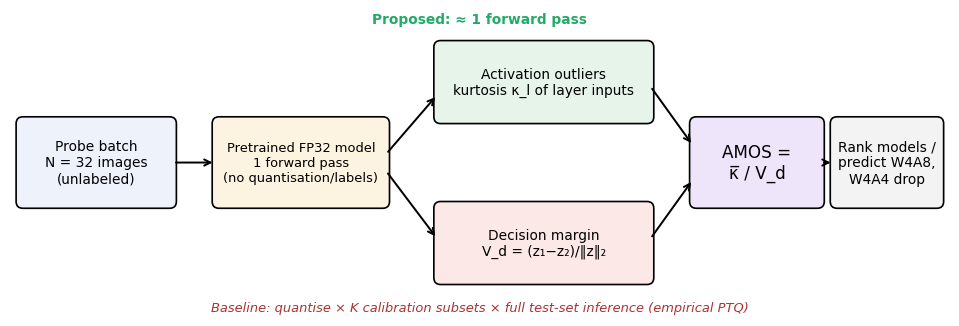

In [ ]:
# FIG 1 — method schematic
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(11, 3.6)); ax.axis("off"); ax.set_xlim(0, 11); ax.set_ylim(0, 3.6); ax.grid(False)
def box(x, y, w, h, text, fc, ec="k", fs=9):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.08", fc=fc, ec=ec, lw=1.1))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs)
def arrow(x1, y1, x2, y2): ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", lw=1.3))
box(0.1, 1.3, 1.8, 1.0, "Probe batch\nN = 32 images\n(unlabeled)", "#eef3fb")
box(2.4, 1.3, 2.0, 1.0, "Pretrained FP32 model\n1 forward pass\n(no quantisation/labels)", "#fdf3e1", fs=8.5)
box(5.0, 2.3, 2.5, 0.9, "Activation outliers\nkurtosis \u03ba_l of layer inputs", "#e6f4ea")
box(5.0, 0.4, 2.5, 0.9, "Decision margin\nV_d = (z\u2081\u2212z\u2082)/\u2016z\u2016\u2082", "#fde8e8")
box(8.0, 1.3, 1.5, 1.0, "AMOS =\n\u03ba\u0305 / V_d", "#efe5fb", fs=11)
box(9.65, 1.3, 1.25, 1.0, "Rank models /\npredict W4A8,\nW4A4 drop", "#f3f3f3")
arrow(1.9, 1.8, 2.4, 1.8); arrow(4.4, 1.9, 5.0, 2.6); arrow(4.4, 1.7, 5.0, 0.9); arrow(7.5, 2.7, 8.0, 2.0); arrow(7.5, 0.9, 8.0, 1.6); arrow(9.5, 1.8, 9.65, 1.8)
ax.text(5.5, 3.45, "Proposed: \u2248 1 forward pass", ha="center", fontsize=9, color="#2a6", weight="bold")
ax.text(5.5, 0.05, "Baseline: quantise \u00d7 K calibration subsets \u00d7 full test-set inference (empirical PTQ)", ha="center", fontsize=8.5, color="#a33", style="italic")
savefig("fig1_method")

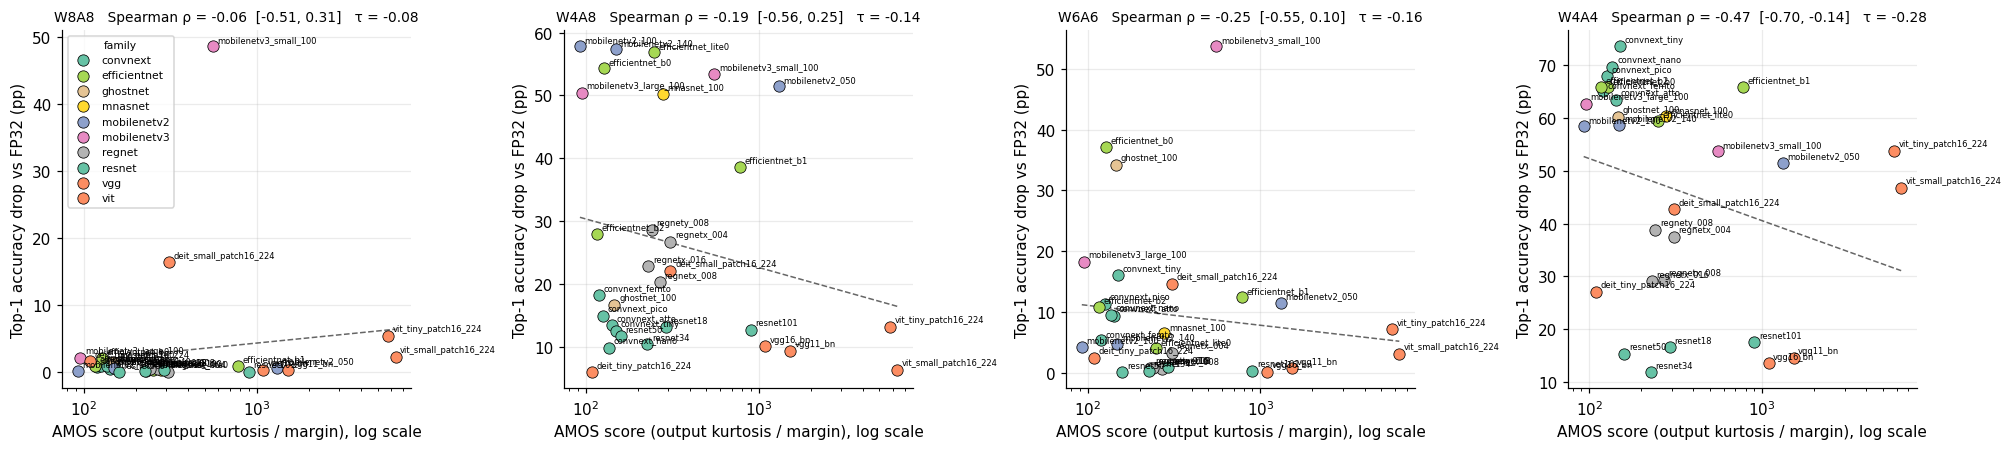

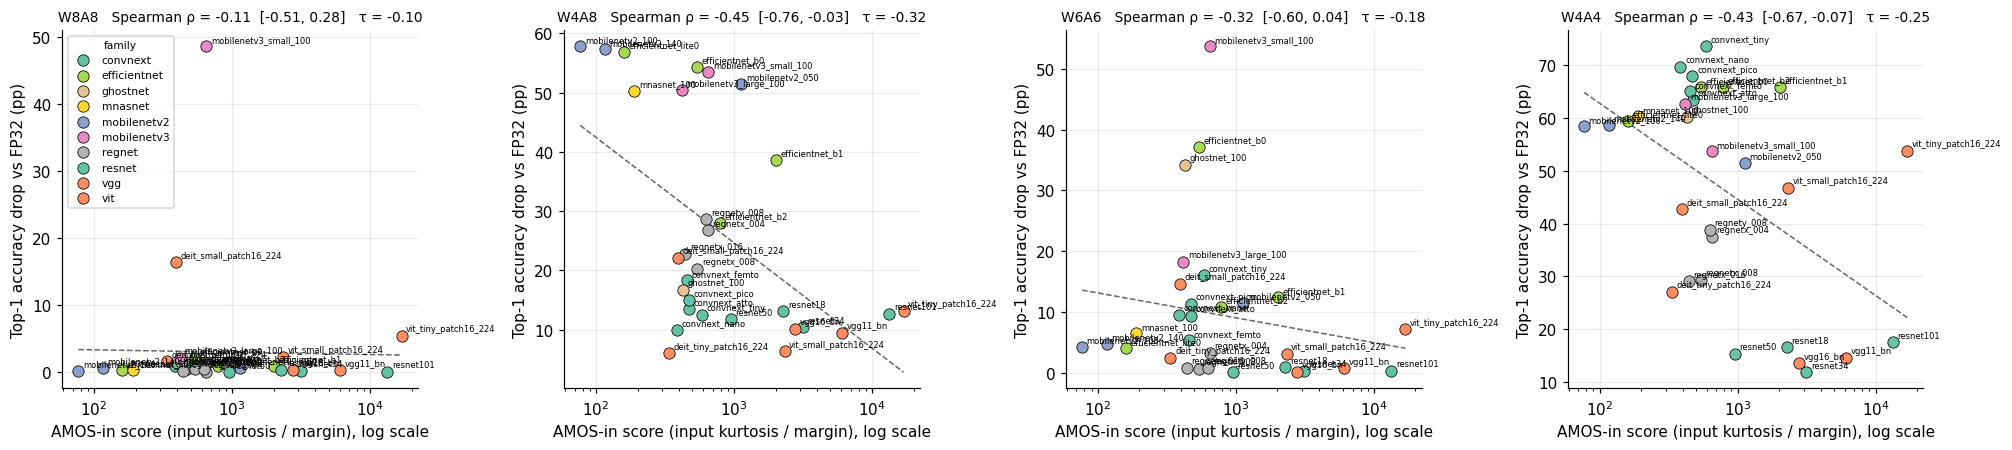

In [ ]:
# FIG 2 — main result: AMOS vs PTQ accuracy drop (+ control W8A8)
def fig_scatter(df, col="AMOS", xlabel="AMOS score (log scale)", name="fig2_amos_vs_drop"):
    fig, axs = plt.subplots(1, len(TAGS), figsize=(4.6 * len(TAGS), 4.2))
    for ax, tag in zip(np.atleast_1d(axs), TAGS):
        for fam, g in df.groupby("family"):
            ax.scatter(g[col], g[f"drop_{tag}"], s=55, color=PAL[fam], edgecolor="k", lw=.5, label=fam, zorder=3)
        for _, r in df.iterrows():
            ax.annotate(r["model"], (r[col], r[f"drop_{tag}"]), fontsize=5.5, xytext=(3, 3), textcoords="offset points")
        x, y = np.log(df[col].values), df[f"drop_{tag}"].values; b = np.polyfit(x, y, 1); xs = np.linspace(x.min(), x.max(), 50)
        ax.plot(np.exp(xs), np.polyval(b, xs), "k--", lw=1, alpha=.6)
        rho, tau, p, lo, hi = corr_stats(df[col], df[f"drop_{tag}"])
        ax.set_xscale("log"); ax.set_title(f"{tag}   Spearman \u03c1 = {rho:.2f}  [{lo:.2f}, {hi:.2f}]   \u03c4 = {tau:.2f}", fontsize=9)
        ax.set_xlabel(xlabel); ax.set_ylabel("Top-1 accuracy drop vs FP32 (pp)")
    np.atleast_1d(axs)[0].legend(fontsize=7, title="family", title_fontsize=7)
    plt.tight_layout(); savefig(name)
fig_scatter(DF, "AMOS_out", "AMOS score (output kurtosis / margin), log scale", "fig2_amos_vs_drop")
fig_scatter(DF, "AMOS", "AMOS-in score (input kurtosis / margin), log scale", "fig2b_amos_in_vs_drop")

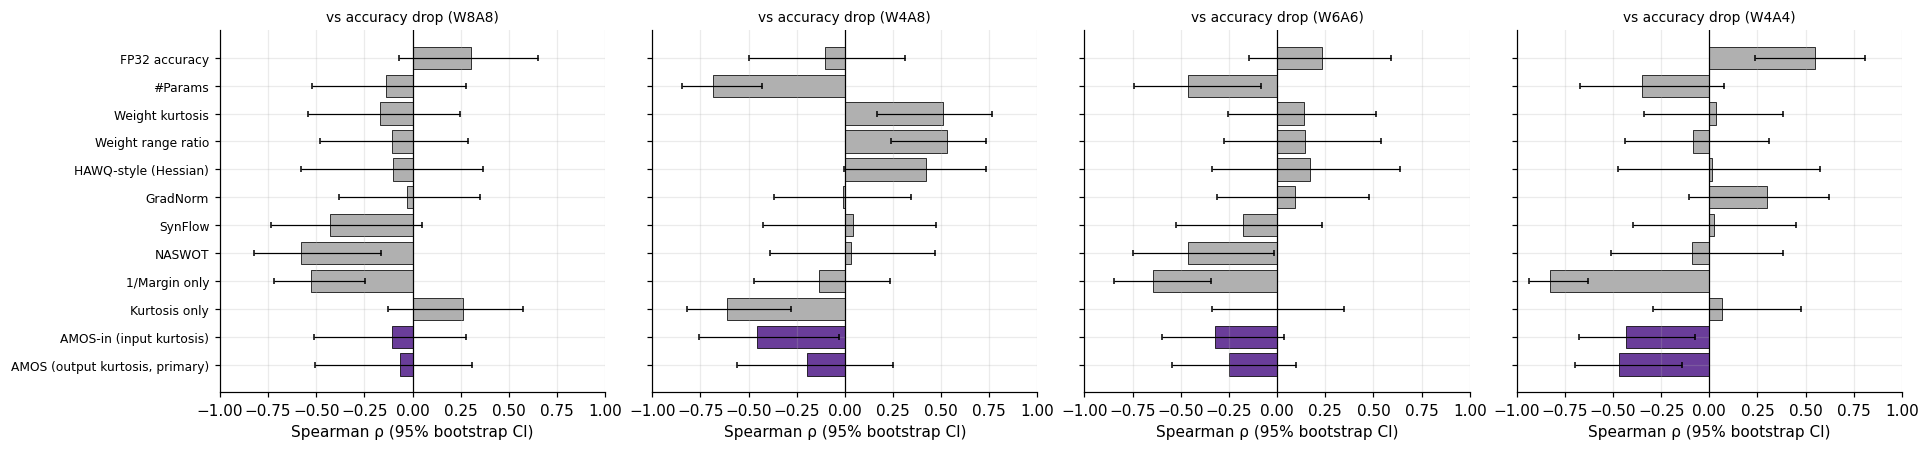

target,drop_W8A8,drop_W4A8,drop_W6A6,drop_W4A4
proxy,,,,
"AMOS (output kurtosis, primary)","-0.06 [-0.51,0.31]","-0.19 [-0.56,0.25]","-0.25 [-0.55,0.10]","-0.47 [-0.70,-0.14]"
AMOS-in (input kurtosis),"-0.11 [-0.51,0.28]","-0.45 [-0.76,-0.03]","-0.32 [-0.60,0.04]","-0.43 [-0.67,-0.07]"
Kurtosis only,"0.26 [-0.13,0.57]","-0.61 [-0.82,-0.28]","-0.00 [-0.34,0.35]","0.07 [-0.29,0.48]"
1/Margin only,"-0.53 [-0.72,-0.25]","-0.14 [-0.47,0.23]","-0.64 [-0.85,-0.34]","-0.83 [-0.94,-0.63]"
NASWOT,"-0.58 [-0.83,-0.16]","0.03 [-0.39,0.47]","-0.46 [-0.75,-0.01]","-0.09 [-0.51,0.38]"
SynFlow,"-0.43 [-0.74,0.05]","0.04 [-0.43,0.47]","-0.18 [-0.52,0.23]","0.02 [-0.39,0.45]"
GradNorm,"-0.03 [-0.38,0.35]","-0.01 [-0.37,0.35]","0.09 [-0.31,0.48]","0.30 [-0.11,0.62]"
HAWQ-style (Hessian),"-0.10 [-0.58,0.37]","0.42 [-0.01,0.74]","0.17 [-0.34,0.64]","0.02 [-0.47,0.57]"
Weight range ratio,"-0.11 [-0.48,0.29]","0.53 [0.24,0.73]","0.14 [-0.27,0.54]","-0.09 [-0.44,0.31]"


In [ ]:
# FIG 3 — comparison with existing proxies (signed Spearman with bootstrap CI)
fig, axs = plt.subplots(1, len(TAGS), figsize=(4.4 * len(TAGS), 4.2), sharey=True)
order = list(PROXIES)
for ax, tag in zip(np.atleast_1d(axs), TAGS):
    d = CORR[CORR.target == f"drop_{tag}"].set_index("proxy").reindex(order)
    cols = ["#6a3d9a" if p.startswith("AMOS") else "#b0b0b0" for p in order]
    ax.barh(range(len(order)), d["rho"], color=cols, edgecolor="k", lw=.5,
            xerr=[(d["rho"] - d["ci_lo"]).clip(lower=0), (d["ci_hi"] - d["rho"]).clip(lower=0)], error_kw=dict(lw=.8, capsize=2))
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=8); ax.invert_yaxis(); ax.axvline(0, color="k", lw=.8)
    ax.set_xlim(-1, 1); ax.set_title(f"vs accuracy drop ({tag})", fontsize=9); ax.set_xlabel("Spearman \u03c1 (95% bootstrap CI)")
plt.tight_layout(); savefig("fig3_proxy_comparison")

# paper table: comparison with existing proxies
tbl = CORR.pivot(index="proxy", columns="target", values="rho").reindex(order)[[f"drop_{t}" for t in TAGS]]
tbl_ci = CORR.assign(txt=lambda d: d.apply(lambda r: f"{r.rho:.2f} [{r.ci_lo:.2f},{r.ci_hi:.2f}]", axis=1)).pivot(index="proxy", columns="target", values="txt").reindex(order)
TABLE_CORR = tbl_ci[[f"drop_{t}" for t in TAGS]]; display(TABLE_CORR)

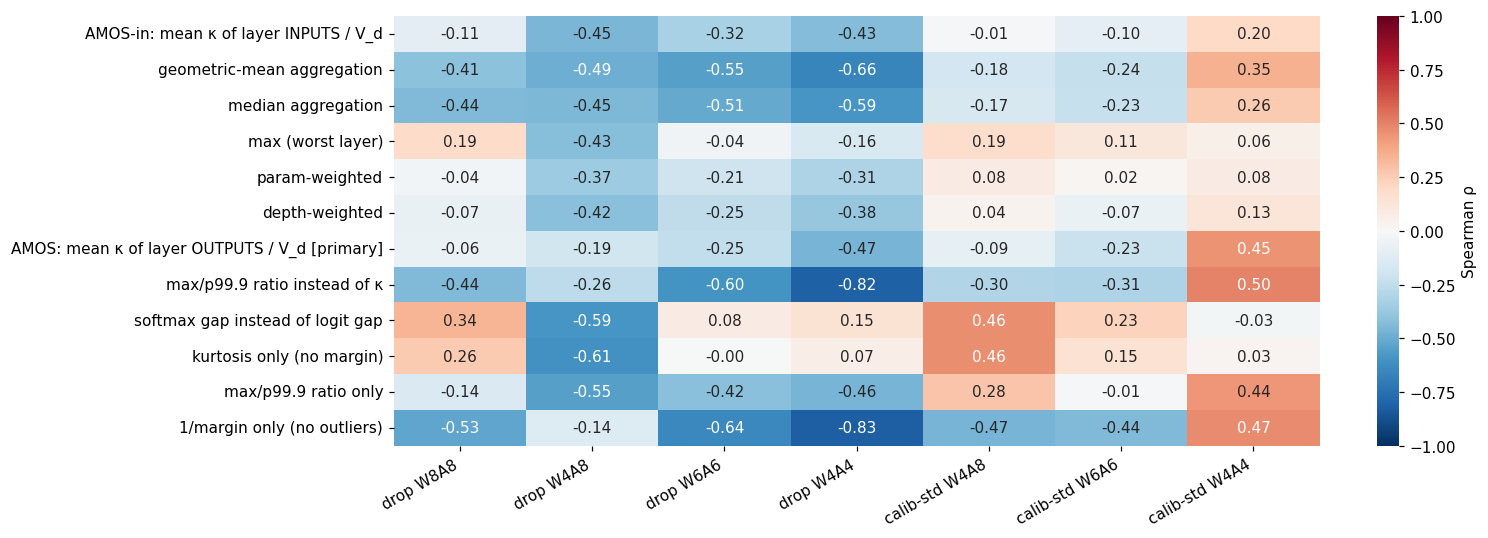

,drop_W8A8,drop_W4A8,drop_W6A6,drop_W4A4,std_W4A8,std_W6A6,std_W4A4
AMOS-in: mean κ of layer INPUTS / V_d,-0.11,-0.45,-0.32,-0.43,-0.01,-0.10,0.20
geometric-mean aggregation,-0.41,-0.49,-0.55,-0.66,-0.18,-0.24,0.35
median aggregation,-0.44,-0.45,-0.51,-0.59,-0.17,-0.23,0.26
max (worst layer),0.19,-0.43,-0.04,-0.16,0.19,0.11,0.06
param-weighted,-0.04,-0.37,-0.21,-0.31,0.08,0.02,0.08
depth-weighted,-0.07,-0.42,-0.25,-0.38,0.04,-0.07,0.13
AMOS: mean κ of layer OUTPUTS / V_d [primary],-0.06,-0.19,-0.25,-0.47,-0.09,-0.23,0.45
max/p99.9 ratio instead of κ,-0.44,-0.26,-0.60,-0.82,-0.30,-0.31,0.50
softmax gap instead of logit gap,0.34,-0.59,0.08,0.15,0.46,0.23,-0.03
kurtosis only (no margin),0.26,-0.61,-0.00,0.07,0.46,0.15,0.03


In [ ]:
# FIG 4 — ablation heatmap (what in AMOS matters?)
VARS = ["AMOS", "AMOS[geo]", "AMOS[median]", "AMOS[max]", "AMOS[param]", "AMOS[depth]", "AMOS_out", "AMOS_omega", "AMOS_pgap", "kurt_only", "omega_only", "inv_margin"]
LABELS = {"AMOS": "AMOS-in: mean \u03ba of layer INPUTS / V_d", "AMOS[geo]": "geometric-mean aggregation", "AMOS[median]": "median aggregation",
          "AMOS[max]": "max (worst layer)", "AMOS[param]": "param-weighted", "AMOS[depth]": "depth-weighted", "AMOS_out": "AMOS: mean \u03ba of layer OUTPUTS / V_d [primary]",
          "AMOS_omega": "max/p99.9 ratio instead of \u03ba", "AMOS_pgap": "softmax gap instead of logit gap",
          "kurt_only": "kurtosis only (no margin)", "omega_only": "max/p99.9 ratio only", "inv_margin": "1/margin only (no outliers)"}
M = pd.DataFrame({tg: [stats.spearmanr(DF[v], DF[tg])[0] for v in VARS] for tg in TARGETS}, index=[LABELS[v] for v in VARS])
fig, ax = plt.subplots(figsize=(1.4 * len(TARGETS) + 4.5, 5)); ax.grid(False)
sns.heatmap(M, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws=dict(label="Spearman \u03c1"))
ax.set_xticklabels([t.replace("drop_", "drop ").replace("std_", "calib-std ") for t in TARGETS], rotation=30, ha="right"); plt.tight_layout(); savefig("fig4_ablation_heatmap")
display(M.round(2))

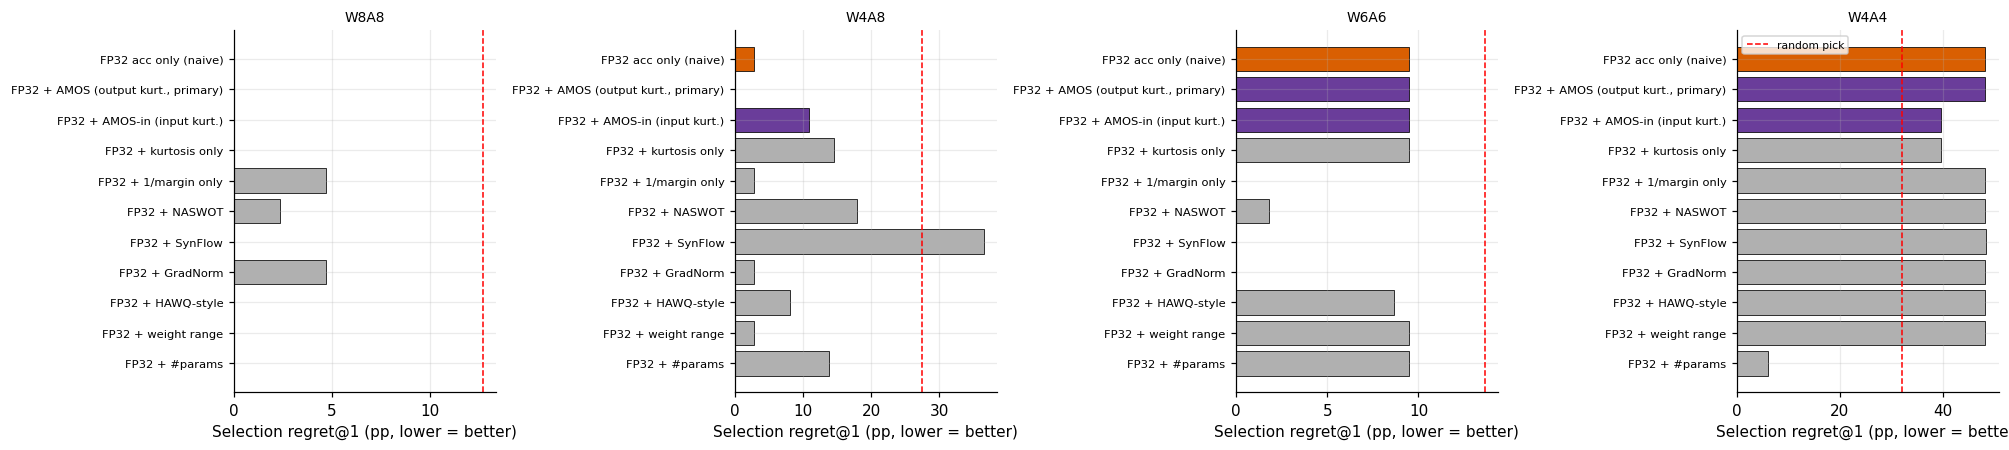

In [ ]:
# FIG 5 — selection regret (leave-one-out)
fig, axs = plt.subplots(1, len(TAGS), figsize=(4.6 * len(TAGS), 4.2), sharey=False)
for ax, tag in zip(np.atleast_1d(axs), TAGS):
    d = REG[(REG.config == tag) & (~REG.method.str.startswith("Random"))].set_index("method").reindex(list(SEL))
    cols = ["#6a3d9a" if "AMOS" in m else ("#d95f02" if m.startswith("FP32 acc") else "#b0b0b0") for m in d.index]
    ax.barh(range(len(d)), d["regret_at1"], color=cols, edgecolor="k", lw=.5)
    rnd = REG[(REG.config == tag) & (REG.method.str.startswith("Random"))]["regret_at1"].iloc[0]; ax.axvline(rnd, color="r", ls="--", lw=1, label="random pick")
    ax.set_yticks(range(len(d))); ax.set_yticklabels(d.index, fontsize=7.5); ax.invert_yaxis(); ax.set_xlabel("Selection regret@1 (pp, lower = better)"); ax.set_title(tag, fontsize=9)
np.atleast_1d(axs)[-1].legend(fontsize=7); plt.tight_layout(); savefig("fig5_selection_regret")

In [ ]:
# CELL — fresh timing on the CURRENT runtime (timings cached in the checkpoint may come from a different device, e.g. GPU earlier / CPU now)
DEVNAME = (torch.cuda.get_device_name(0) if device == "cuda" else "CPU")
TK = Ckpt(f"{WORKDIR}/timing_{TRACK}_{MODE}_{device}.json")
def med(fn, reps=3):
    try:
        ts = []
        for _ in range(reps):
            t0 = sync_time(); fn(); ts.append(sync_time() - t0)
        return float(np.median(ts))
    except Exception as e:
        print("   timing failed:", str(e)[:70]); return float("nan")
for name in tqdm(list(ZOO), desc=f"timing on {DEVNAME}"):
    if TK.has(name): continue
    model = ZOO[name]; x, y = get_probe(model, 0, 32); rec = {}
    with torch.no_grad(): model(x)                                    # warm-up
    def amos_fn():
        ls, z = layer_stats(model, x); amos_variants(ls, margin_stats(z))
    rec["t_amos"] = med(amos_fn, 5)
    rec["t_naswot"] = med(lambda: naswot(model, x))
    rec["t_synflow"] = med(lambda: synflow(model, x.shape))
    xb, yb = (x, y) if TRACK == "cifar100" else (x[:16], y[:16])
    rec["t_gradnorm"] = med(lambda: grad_norm(model, xb, yb))
    rec["t_hawq"] = med(lambda: hawq_score(model, xb, yb, n_iter=8 if TRACK == "cifar100" else 4), 1)
    for (w, a) in QUANT_CONFIGS: rec[f"sec_W{w}A{a}"] = run_ptq(FOLDED[name], w, a, seed=1000)[1]
    TK.put(name, rec)
for k in ["t_amos", "t_naswot", "t_synflow", "t_gradnorm", "t_hawq"] + [f"sec_{t}" for t in TAGS]:
    DF[k] = [TK.get(m)[k] for m in DF["model"]]
print(f"All timings in Fig 6 / speed-up numbers were measured on: {DEVNAME} (report this in the paper).")

timing on Tesla T4:   0%|          | 0/30 [00:00<?, ?it/s]

All timings in Fig 6 / speed-up numbers were measured on: Tesla T4 (report this in the paper).


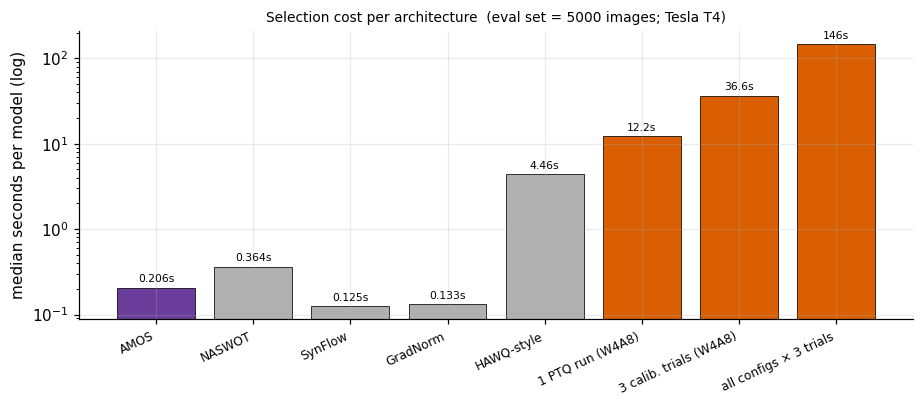

Median speed-up of AMOS vs 3-trial empirical PTQ (W4A8) at n_eval=5000: 175x
NOTE: the empirical cost scales with n_eval; the draft's '1000x' only holds for large eval sets. Report the exact setting.


In [ ]:
# FIG 6 — cost / speed comparison (measured on THIS hardware)
cost = {"AMOS": DF["t_amos"].median(), "NASWOT": DF["t_naswot"].median(), "SynFlow": DF["t_synflow"].median(),
        "GradNorm": DF["t_gradnorm"].median(), "HAWQ-style": DF["t_hawq"].median(),
        f"1 PTQ run ({MAIN})": DF[f"sec_{MAIN}"].median(),
        f"{PRESET['n_trials']} calib. trials ({MAIN})": DF[f"sec_{MAIN}"].median() * PRESET["n_trials"],
        f"all configs \u00d7 {PRESET['n_trials']} trials": sum(DF[f"sec_{t}"].median() for t in TAGS) * PRESET["n_trials"]}
fig, ax = plt.subplots(figsize=(8.5, 3.8))
cols = ["#6a3d9a"] + ["#b0b0b0"] * 4 + ["#d95f02"] * 3
ax.bar(range(len(cost)), list(cost.values()), color=cols, edgecolor="k", lw=.5); ax.set_yscale("log")
ax.set_xticks(range(len(cost))); ax.set_xticklabels(list(cost), rotation=25, ha="right", fontsize=8); ax.set_ylabel("median seconds per model (log)")
for i, v in enumerate(cost.values()): ax.text(i, v * 1.15, f"{v:.3g}s", ha="center", fontsize=7)
ax.set_title(f"Selection cost per architecture  (eval set = {PRESET['n_eval']} images; {DEVNAME})", fontsize=9); plt.tight_layout(); savefig("fig6_cost")
SPEEDUP = (DF[f"sec_{MAIN}"] * PRESET["n_trials"] / DF["t_amos"]).median()
print(f"Median speed-up of AMOS vs {PRESET['n_trials']}-trial empirical PTQ ({MAIN}) at n_eval={PRESET['n_eval']}: {SPEEDUP:,.0f}x")
print("NOTE: the empirical cost scales with n_eval; the draft's '1000x' only holds for large eval sets. Report the exact setting.")

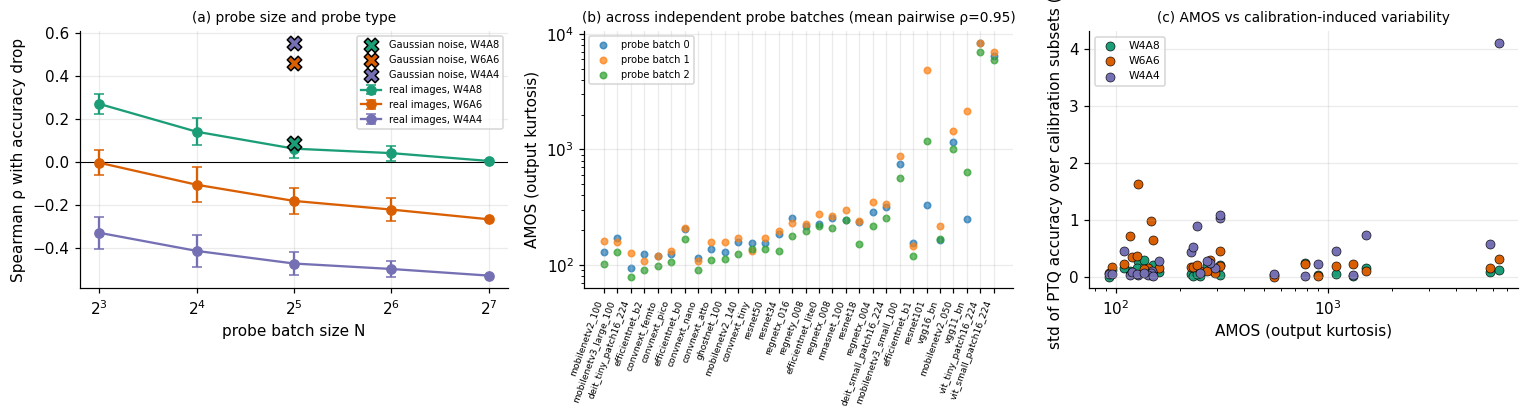

In [ ]:
# FIG 7 — probe robustness: size, type (real vs Gaussian noise), seed stability
fig, axs = plt.subplots(1, 3, figsize=(14, 3.9))
ax = axs[0]
for tag, c in zip(TAGS[1:], TAG_COLS):
    d = ABL[(ABL.variant == PRIMARY) & (ABL.kind == "real") & (ABL.tag == tag)]
    ax.errorbar(d["n"], d["rho_mean"], d["rho_sd"], marker="o", color=c, capsize=3, label=f"real images, {tag}")
    g = ABL[(ABL.variant == PRIMARY) & (ABL.kind == "gauss") & (ABL.tag == tag)]
    ax.scatter(g["n"], g["rho_mean"], marker="X", s=90, color=c, edgecolor="k", label=f"Gaussian noise, {tag}", zorder=5)
ax.set_xticks(sorted(ABL["n"].unique())); ax.set_xscale("log", base=2) if ABL["rho_mean"].notna().any() else None; ax.set_xlabel("probe batch size N"); ax.set_ylabel("Spearman \u03c1 with accuracy drop"); ax.axhline(0, color="k", lw=.7)
ax.set_title("(a) probe size and probe type", fontsize=9); ax.legend(fontsize=6.5)
ax = axs[1]; srt = DF.sort_values(PRIMARY); pos = {m: i for i, m in enumerate(srt["model"])}
for s in range(ABL_SEEDS):
    ax.scatter([pos[m] for m in DF["model"]], seed_mat[s], s=18, alpha=.7, label=f"probe batch {s}")
ax.set_yscale("log"); ax.set_xticks(range(len(srt))); ax.set_xticklabels(srt["model"], rotation=70, ha="right", fontsize=6)
ax.set_ylabel("AMOS (output kurtosis)"); ax.set_title(f"(b) across independent probe batches (mean pairwise \u03c1={np.mean(pair):.2f})", fontsize=9); ax.legend(fontsize=6.5)
ax = axs[2]
for tag, c in zip(TAGS[1:], TAG_COLS):
    ax.scatter(DF[PRIMARY], DF[f"std_{tag}"], color=c, s=35, edgecolor="k", lw=.4, label=tag)
ax.set_xscale("log"); ax.set_xlabel("AMOS (output kurtosis)"); ax.set_ylabel("std of PTQ accuracy over calibration subsets (pp)")
ax.set_title("(c) AMOS vs calibration-induced variability", fontsize=9); ax.legend(fontsize=7)
plt.tight_layout(); savefig("fig7_probe_robustness")

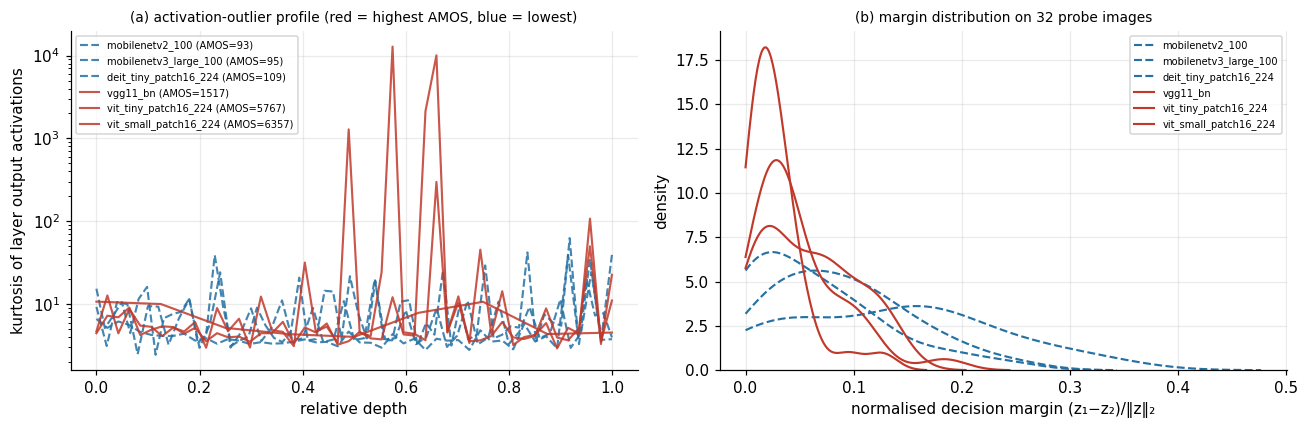

In [ ]:
# FIG 8 — why it works: per-layer OUTPUT-kurtosis profiles and margin distributions (3 lowest / 3 highest AMOS)
srt = DF.sort_values(PRIMARY); pick = list(srt["model"].iloc[:3]) + list(srt["model"].iloc[-3:])
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for m in pick:
    rec = CK.get(f"proxy|{m}|real|n32|s0"); k = [l["k_out"] for l in rec["layers"]][1:-1]
    hi = m in list(srt["model"].iloc[-3:]); c = "#c0392b" if hi else "#2471a3"
    axs[0].plot(np.linspace(0, 1, len(k)), k, color=c, alpha=.85, lw=1.4, ls="-" if hi else "--", label=f"{m} (AMOS={DF.set_index('model').loc[m, PRIMARY]:.0f})")
    sns.kdeplot(np.array(rec["gaps"]), ax=axs[1], color=c, ls="-" if hi else "--", lw=1.4, label=m, clip=(0, None))
axs[0].set_yscale("log"); axs[0].set_xlabel("relative depth"); axs[0].set_ylabel("kurtosis of layer output activations"); axs[0].legend(fontsize=6.5)
axs[0].set_title("(a) activation-outlier profile (red = highest AMOS, blue = lowest)", fontsize=9)
axs[1].set_xlabel("normalised decision margin (z\u2081\u2212z\u2082)/\u2016z\u2016\u2082"); axs[1].set_ylabel("density"); axs[1].set_title("(b) margin distribution on 32 probe images", fontsize=9); axs[1].legend(fontsize=6.5)
plt.tight_layout(); savefig("fig8_mechanism")

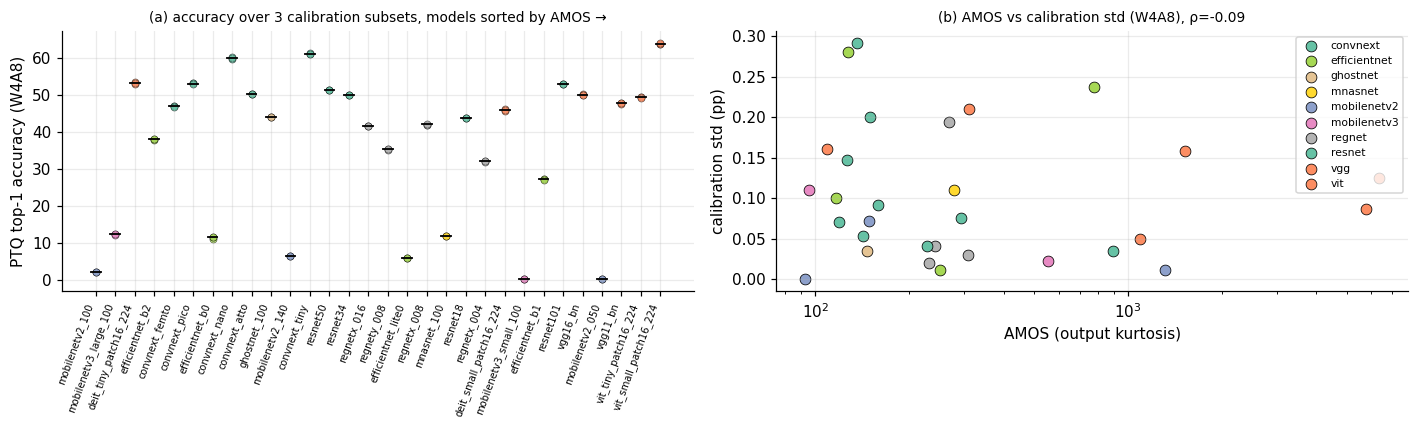

In [ ]:
# FIG 9 — calibration-induced variability (the original proposal's quantity)
tag = MAIN; srt = DF.sort_values(PRIMARY).reset_index(drop=True)
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
ax = axs[0]
for i, r in srt.iterrows():
    ax.scatter([i] * len(r[f"accs_{tag}"]), r[f"accs_{tag}"], color=PAL[r["family"]], s=22, alpha=.8, edgecolor="k", lw=.3)
    ax.plot([i - .25, i + .25], [r[f"acc_{tag}"]] * 2, color="k", lw=1.2)
ax.set_xticks(range(len(srt))); ax.set_xticklabels(srt["model"], rotation=70, ha="right", fontsize=6.5); ax.set_ylabel(f"PTQ top-1 accuracy ({tag})")
ax.set_title(f"(a) accuracy over {PRESET['n_trials']} calibration subsets, models sorted by AMOS \u2192", fontsize=9)
ax = axs[1]
for fam, g in DF.groupby("family"): ax.scatter(g[PRIMARY], g[f"std_{tag}"], color=PAL[fam], s=50, edgecolor="k", lw=.5, label=fam)
rho = stats.spearmanr(DF[PRIMARY], DF[f"std_{tag}"])[0]; ax.set_xscale("log"); ax.set_xlabel("AMOS (output kurtosis)"); ax.set_ylabel("calibration std (pp)")
ax.set_title(f"(b) AMOS vs calibration std ({tag}), \u03c1={rho:.2f}", fontsize=9); ax.legend(fontsize=7)
plt.tight_layout(); savefig("fig9_calibration_variability")

## 8. Tables, claims check, related work, export

In [ ]:
# TABLES + HONEST CLAIMS CHECK
os.makedirs(f"{FIGDIR}/tables", exist_ok=True)
main_cols = ["model", "family", "params_M", "fp32_acc", "AMOS_out", "AMOS"] + [f"acc_{t}" for t in TAGS] + [f"drop_{t}" for t in TAGS]
T_MAIN = DF[main_cols].sort_values(PRIMARY).round(2)
exports = {"table_main": T_MAIN, "table_corr_ci": TABLE_CORR.reset_index(), "table_corr_full": CORR.round(3), "table_family_adjusted": FAM.round(3),
           "table_regret": REG.round(3), "table_ablation_probe": ABL.round(3), "table_ablation_variants": M.round(3).reset_index(), "table_all_raw": DF.drop(columns=[c for c in DF if c.startswith("accs_")])}
for k, v in exports.items():
    v.to_csv(f"{FIGDIR}/tables/{k}.csv", index=False)
    try: open(f"{FIGDIR}/tables/{k}.tex", "w").write(v.to_latex(index=False, float_format="%.2f"))
    except Exception as e: print("latex export skipped for", k, str(e)[:60])

print("=" * 78); print("CLAIMS CHECK (draft proposal targets vs what this run measured)"); print("=" * 78)
for tag in TAGS[1:]:
    r = CORR[(CORR.proxy == "AMOS (output kurtosis, primary)") & (CORR.target == f"drop_{tag}")].iloc[0]
    best = CORR[(CORR.target == f"drop_{tag}") & (~CORR.proxy.str.startswith("AMOS"))].assign(a=lambda d: d.rho.abs()).sort_values("a", ascending=False).iloc[0]
    fa = FAM[(FAM.proxy == "AMOS (output kurtosis, primary)") & (FAM.target == f"drop_{tag}")]["rho_family_adj"].iloc[0]
    print(f"[{tag}] AMOS(primary) rho={r.rho:+.2f} (95% CI {r.ci_lo:+.2f}..{r.ci_hi:+.2f}); family-adjusted {fa:+.2f}; target >0.80: {'MET' if r.rho > .8 else 'NOT MET'};"
          f" strongest baseline = {best.proxy} ({best.rho:+.2f})")
    rg = REG[(REG.config == tag)].set_index("method")["regret_at1"]
    print(f"        regret@1: AMOS {rg['FP32 + AMOS (output kurt., primary)']:.2f} vs FP32-only {rg['FP32 acc only (naive)']:.2f} vs random {rg['Random pick (expected)']:.2f} pp")
print(f"[speed] median speed-up vs {PRESET['n_trials']}-trial PTQ at n_eval={PRESET['n_eval']}: {SPEEDUP:,.0f}x (1000x target: {'MET' if SPEEDUP >= 1000 else 'NOT MET at this eval size'})")
print(f"[stability] mean pairwise rho of AMOS rankings across probe batches: {np.mean(pair):.2f}")
print("\nIf AMOS is not above the best baseline, say so: the paper can still be a rigorous negative/partial result"
      " (e.g. 'weight-range dispersion predicts W4 collapse; activation kurtosis does not') - see the ablation heatmap for what carries the signal.")

CLAIMS CHECK (draft proposal targets vs what this run measured)
[W4A8] AMOS(primary) rho=-0.19 (95% CI -0.56..+0.25); family-adjusted +0.09; target >0.80: NOT MET; strongest baseline = #Params (-0.68)
        regret@1: AMOS 0.00 vs FP32-only 2.75 vs random 27.52 pp
[W6A6] AMOS(primary) rho=-0.25 (95% CI -0.55..+0.10); family-adjusted +0.34; target >0.80: NOT MET; strongest baseline = 1/Margin only (-0.64)
        regret@1: AMOS 9.47 vs FP32-only 9.47 vs random 13.66 pp
[W4A4] AMOS(primary) rho=-0.47 (95% CI -0.70..-0.14); family-adjusted +0.06; target >0.80: NOT MET; strongest baseline = 1/Margin only (-0.83)
        regret@1: AMOS 48.36 vs FP32-only 48.36 vs random 32.14 pp
[speed] median speed-up vs 3-trial PTQ at n_eval=5000: 175x (1000x target: NOT MET at this eval size)
[stability] mean pairwise rho of AMOS rankings across probe batches: 0.95

If AMOS is not above the best baseline, say so: the paper can still be a rigorous negative/partial result (e.g. 'weight-range dispersion pr

## 8b. Diagnostics: is AMOS just a proxy for model size or architecture family?
A proxy that only separates "VGG vs depthwise-separable nets" or "big vs small models" is not a general predictor. These checks are the ones a reviewer will ask for: partial correlation controlling for #params, correlation when one family is dropped, family-adjusted correlation, leave-one-**family**-out prediction of the quantised accuracy, and a Holm correction over all ablation variants (the heatmap is 12 variants x 5 targets, so some large |rho| are expected by chance).

In [ ]:
# CELL — confound and held-out diagnostics
def partial_spearman(x, y, z):
    if len(x) < 4: return float("nan")
    rx, ry, rz = [stats.rankdata(np.asarray(v, float)) for v in (x, y, z)]
    ex = rx - np.polyval(np.polyfit(rz, rx, 1), rz); ey = ry - np.polyval(np.polyfit(rz, ry, 1), rz)
    return stats.pearsonr(ex, ey)[0]

CANDS = {"AMOS (input kurtosis)": "AMOS", "AMOS_out (draft: output kurtosis)": "AMOS_out", "kurtosis only": "kurt_only",
         "HAWQ-style": "hawq_s", "GradNorm": "gradnorm", "weight range ratio": "w_range", "#params": "params_M"}
rows = []
for nm, col in CANDS.items():
    for tg in [f"drop_{t}" for t in TAGS[1:]]:
        d = DF[list(dict.fromkeys([col, tg, "family", "params_M"]))].dropna()
        folds = [stats.spearmanr(d[d.family != f][col], d[d.family != f][tg])[0] for f in d.family.unique() if (d.family != f).sum() >= 5]
        rows.append(dict(proxy=nm, target=tg, pooled=stats.spearmanr(d[col], d[tg])[0], family_adjusted=family_adjusted(DF, col, tg),
                         partial_given_params=(partial_spearman(d[col], d[tg], d["params_M"]) if col != "params_M" else np.nan),
                         drop_one_family_min=(min(folds) if folds else np.nan), drop_one_family_max=(max(folds) if folds else np.nan)))
DIAG = pd.DataFrame(rows); display(DIAG.round(2))
print("Family means (is the proxy just ordering architecture families?):")
display(DF.groupby("family")[["params_M", "AMOS", "AMOS_out"] + [f"drop_{t}" for t in TAGS[1:]]].mean().round(2))

# leave-one-FAMILY-out: can a proxy predict the PTQ accuracy of an architecture family it has never seen?
def lofo_table(df, feature_sets, tag, lam=1e-2):
    y = df[f"acc_{tag}"].values; out = []
    base = np.zeros(len(df))
    for fam in df.family.unique():
        te = (df.family == fam).values; base[te] = y[~te].mean()
    out.append(dict(method="train-mean (no model)", tag=tag, MAE_pp=np.abs(base - y).mean(), rho=np.nan))
    for name, feats in feature_sets.items():
        d = df.dropna(subset=feats); yy = d[f"acc_{tag}"].values; X = d[feats].values.astype(float); pred = np.zeros(len(d))
        for fam in d.family.unique():
            te = (d.family == fam).values; tr = ~te; mu, sd = X[tr].mean(0), X[tr].std(0) + 1e-9
            A = np.c_[np.ones(tr.sum()), (X[tr] - mu) / sd]; R = np.eye(A.shape[1]) * lam; R[0, 0] = 0
            w = np.linalg.solve(A.T @ A + R, A.T @ yy[tr]); pred[te] = np.c_[np.ones(te.sum()), (X[te] - mu) / sd] @ w
        out.append(dict(method=name, tag=tag, MAE_pp=np.abs(pred - yy).mean(), rho=stats.spearmanr(pred, yy)[0]))
    return pd.DataFrame(out)
LOFO = pd.concat([lofo_table(DF, SEL, t) for t in TAGS[1:]])
display(LOFO.pivot(index="method", columns="tag", values="MAE_pp").round(2)); print("^ held-out-family MAE of predicted PTQ accuracy (pp, lower = better)")
display(LOFO.pivot(index="method", columns="tag", values="rho").round(2)); print("^ held-out-family Spearman between predicted and true PTQ accuracy")

# Holm correction over every (variant x target) test in the ablation heatmap
pairs = sorted([(v, tg, stats.spearmanr(DF[v], DF[tg])[1]) for v in VARS for tg in TARGETS], key=lambda t: t[2]); m = len(pairs); surv = []
for i, (v, tg, p) in enumerate(pairs):
    if p <= 0.05 / (m - i): surv.append((v, tg, round(p, 6)))
    else: break
print(f"\nHolm-corrected (alpha=.05, {m} tests): {len(surv)} survive ->", surv)
DIAG.to_csv(f"{FIGDIR}/tables/diagnostics_confounds.csv", index=False); LOFO.to_csv(f"{FIGDIR}/tables/diagnostics_lofo.csv", index=False)

,proxy,target,pooled,family_adjusted,partial_given_params,drop_one_family_min,drop_one_family_max
0,AMOS (input kurtosis),drop_W4A8,-0.45,-0.19,-0.21,-0.60,-0.35
1,AMOS (input kurtosis),drop_W6A6,-0.32,0.35,-0.14,-0.41,-0.08
2,AMOS (input kurtosis),drop_W4A4,-0.43,0.30,-0.33,-0.54,-0.21
3,AMOS_out (draft: output kurtosis),drop_W4A8,-0.19,0.09,-0.02,-0.34,-0.07
4,AMOS_out (draft: output kurtosis),drop_W6A6,-0.25,0.34,-0.15,-0.35,-0.15
5,AMOS_out (draft: output kurtosis),drop_W4A4,-0.47,0.06,-0.42,-0.59,-0.30
6,kurtosis only,drop_W4A8,-0.61,-0.16,-0.30,-0.70,-0.49
7,kurtosis only,drop_W6A6,-0.00,0.33,0.44,-0.13,0.15
8,kurtosis only,drop_W4A4,0.07,0.73,0.41,-0.18,0.25
9,HAWQ-style,drop_W4A8,0.42,0.06,0.16,0.24,0.58


Family means (is the proxy just ordering architecture families?):


,params_M,AMOS,AMOS_out,drop_W4A8,drop_W6A6,drop_W4A4
family,,,,,,
convnext,12.43,473.26,134.63,13.83,10.36,67.97
efficientnet,6.71,875.33,317.93,44.46,16.13,64.32
ghostnet,5.18,425.77,146.76,16.70,34.24,60.23
mnasnet,4.38,189.86,278.67,50.25,6.52,60.37
mobilenetv2,3.86,441.29,517.51,55.53,6.91,56.25
mobilenetv3,4.01,533.99,325.49,51.94,35.98,58.23
regnet,6.97,565.31,262.01,24.64,1.45,33.70
resnet,25.90,4929.34,394.28,11.99,0.47,15.35
vgg,135.62,4409.95,1302.83,9.77,0.53,14.10


tag,W4A4,W4A8,W6A6
method,,,
FP32 + #params,15.85,15.60,10.34
FP32 + 1/margin only,15.95,17.92,9.59
"FP32 + AMOS (output kurt., primary)",20.93,17.97,10.52
FP32 + AMOS-in (input kurt.),17.58,15.10,10.39
FP32 + GradNorm,19.46,18.29,10.24
FP32 + HAWQ-style,23.83,18.80,5.75
FP32 + NASWOT,24.50,24.44,13.09
FP32 + SynFlow,23.12,24.23,12.58
FP32 + kurtosis only,20.52,15.89,10.68


^ held-out-family MAE of predicted PTQ accuracy (pp, lower = better)


tag,W4A4,W4A8,W6A6
method,,,
FP32 + #params,0.46,0.49,0.36
FP32 + 1/margin only,0.41,0.07,0.43
"FP32 + AMOS (output kurt., primary)",-0.31,0.18,0.13
FP32 + AMOS-in (input kurt.),-0.03,0.54,0.15
FP32 + GradNorm,-0.41,0.09,0.04
FP32 + HAWQ-style,-0.25,0.02,-0.05
FP32 + NASWOT,-0.43,-0.60,0.23
FP32 + SynFlow,-0.76,-0.57,-0.10
FP32 + kurtosis only,-0.48,0.50,0.07


^ held-out-family Spearman between predicted and true PTQ accuracy

Holm-corrected (alpha=.05, 84 tests): 8 survive -> [('inv_margin', 'drop_W4A4', np.float64(0.0)), ('AMOS_omega', 'drop_W4A4', np.float64(0.0)), ('AMOS[geo]', 'drop_W4A4', np.float64(7.8e-05)), ('inv_margin', 'drop_W6A6', np.float64(0.000125)), ('kurt_only', 'drop_W4A8', np.float64(0.000352)), ('AMOS_omega', 'drop_W6A6', np.float64(0.000486)), ('AMOS[median]', 'drop_W4A4', np.float64(0.000569)), ('AMOS_pgap', 'drop_W4A8', np.float64(0.000618))]


## 8c. Follow-up diagnostics: what carries the AMOS_out signal?
Three questions the 8b results raise: (1) is the **margin term** doing anything once outliers are measured on layer *outputs*? (2) does AMOS_out add anything beyond the **data-free weight-range ratio**? (3) does it still help when the easy win (the large VGGs) is removed, i.e. under an **edge parameter budget**?

In [ ]:
# CELL — component ablation, comparison with the data-free weight-range baseline, budget-constrained selection
def seed0(m): return CK.get(f"proxy|{m}|real|n32|s0")
DF["kout_only"] = [np.mean([l["k_out"] for l in seed0(m)["layers"]][1:-1]) for m in DF["model"]]
DF["kin_only"]  = [np.mean([l["k_in"]  for l in seed0(m)["layers"]][1:-1]) for m in DF["model"]]
VAR2 = {"k_out only (no margin)": "kout_only", "AMOS_out = k_out / V_d": "AMOS_out", "1/V_d only (no outliers)": "inv_margin",
        "weight range ratio (data-free)": "w_range", "#params": "params_M"}
rows = []
for nm, col in VAR2.items():
    for tg in ["drop_W4A8", "drop_W4A4"]:
        d = DF[list(dict.fromkeys([col, tg, "family", "params_M", "w_range"]))].dropna()
        rows.append(dict(variant=nm, target=tg, pooled=stats.spearmanr(d[col], d[tg])[0], family_adjusted=family_adjusted(DF, col, tg),
                         partial_given_params=(partial_spearman(d[col], d[tg], d["params_M"]) if col != "params_M" else np.nan),
                         partial_given_wrange=(partial_spearman(d[col], d[tg], d["w_range"]) if col != "w_range" else np.nan)))
COMP = pd.DataFrame(rows); display(COMP.round(2))
print(f"rho(AMOS_out, weight range ratio) pooled = {stats.spearmanr(DF['AMOS_out'], DF['w_range'])[0]:.2f} | "
      f"rho(k_out only, weight range ratio) = {stats.spearmanr(DF['kout_only'], DF['w_range'])[0]:.2f}   (high => AMOS_out may just be a noisy data-dependent copy of the weight-range baseline)")

DF["f_kout"] = np.log(DF["kout_only"])
SETS2 = {"FP32 acc only": ["f_fp32"], "FP32 + weight range": ["f_fp32", "f_wrange"], "FP32 + AMOS_out": ["f_fp32", "f_AMOS_out"],
         "FP32 + k_out only (no margin)": ["f_fp32", "f_kout"], "FP32 + weight range + AMOS_out": ["f_fp32", "f_wrange", "f_AMOS_out"],
         "FP32 + weight range + k_out only": ["f_fp32", "f_wrange", "f_kout"]}
L2 = pd.concat([lofo_table(DF, SETS2, t) for t in TAGS[1:]])
print("Leave-one-family-out MAE (pp) of predicted PTQ accuracy:"); display(L2.pivot(index="method", columns="tag", values="MAE_pp").round(2))
print("Leave-one-family-out Spearman:"); display(L2.pivot(index="method", columns="tag", values="rho").round(2))

# edge-budget selection: drop everything above BUDGET_M million parameters (removes the large VGGs that win trivially)
BUDGET_M = 3.0 if TRACK == "cifar100" else 6.0
sub = DF[DF["params_M"] <= BUDGET_M].reset_index(drop=True)
print(f"\nBudget-constrained pool: {len(sub)} models <= {BUDGET_M}M params:", list(sub["model"]))
for nm, col in {"AMOS_out": "AMOS_out", "AMOS (input)": "AMOS", "weight range": "w_range", "#params": "params_M"}.items():
    print(f"  {nm:14s} rho vs drop W4A4 = {stats.spearmanr(sub[col], sub['drop_W4A4'])[0]:+.2f} | vs drop W4A8 = {stats.spearmanr(sub[col], sub['drop_W4A8'])[0]:+.2f}")
REG_B = regret_table(sub)
display(REG_B.pivot(index="method", columns="config", values="regret_at1").round(2)); print("^ budget-pool LOO regret@1 (pp)")
display(REG_B.pivot(index="method", columns="config", values="loo_rho").round(2)); print("^ budget-pool LOO Spearman")
COMP.to_csv(f"{FIGDIR}/tables/diagnostics_components.csv", index=False); L2.to_csv(f"{FIGDIR}/tables/diagnostics_lofo_components.csv", index=False); REG_B.to_csv(f"{FIGDIR}/tables/regret_budget_pool.csv", index=False)

,variant,target,pooled,family_adjusted,partial_given_params,partial_given_wrange
0,k_out only (no margin),drop_W4A8,0.10,0.28,0.08,0.24
1,k_out only (no margin),drop_W4A4,0.65,0.48,0.67,0.65
2,AMOS_out = k_out / V_d,drop_W4A8,-0.19,0.09,-0.02,-0.33
3,AMOS_out = k_out / V_d,drop_W4A4,-0.47,0.06,-0.42,-0.46
4,1/V_d only (no outliers),drop_W4A8,-0.14,-0.21,-0.07,-0.39
5,1/V_d only (no outliers),drop_W4A4,-0.83,-0.42,-0.84,-0.85
6,weight range ratio (data-free),drop_W4A8,0.53,-0.05,0.57,NaN
7,weight range ratio (data-free),drop_W4A4,-0.09,0.30,-0.16,NaN
8,#params,drop_W4A8,-0.68,-0.26,NaN,-0.70
9,#params,drop_W4A4,-0.35,0.61,NaN,-0.37


rho(AMOS_out, weight range ratio) pooled = 0.16 | rho(k_out only, weight range ratio) = -0.19   (high => AMOS_out may just be a noisy data-dependent copy of the weight-range baseline)
Leave-one-family-out MAE (pp) of predicted PTQ accuracy:


tag,W4A4,W4A8,W6A6
method,,,
FP32 + AMOS_out,20.93,17.97,10.52
FP32 + k_out only (no margin),25.43,20.88,13.14
FP32 + weight range,19.34,19.11,6.31
FP32 + weight range + AMOS_out,19.72,19.76,6.87
FP32 + weight range + k_out only,26.81,22.49,7.54
FP32 acc only,20.38,17.47,10.04
train-mean (no model),19.30,18.99,9.24


Leave-one-family-out Spearman:


tag,W4A4,W4A8,W6A6
method,,,
FP32 + AMOS_out,-0.31,0.18,0.13
FP32 + k_out only (no margin),-0.50,-0.03,0.19
FP32 + weight range,-0.04,0.23,0.27
FP32 + weight range + AMOS_out,0.13,0.18,0.27
FP32 + weight range + k_out only,-0.16,-0.01,0.22
FP32 acc only,-0.69,0.18,0.12
train-mean (no model),NaN,NaN,NaN



Budget-constrained pool: 13 models <= 6.0M params: ['mobilenetv2_050', 'mobilenetv2_100', 'mobilenetv3_small_100', 'mobilenetv3_large_100', 'efficientnet_b0', 'efficientnet_lite0', 'mnasnet_100', 'ghostnet_100', 'regnetx_004', 'convnext_atto', 'convnext_femto', 'vit_tiny_patch16_224', 'deit_tiny_patch16_224']
  AMOS_out       rho vs drop W4A4 = -0.39 | vs drop W4A8 = -0.12
  AMOS (input)   rho vs drop W4A4 = -0.19 | vs drop W4A8 = -0.27
  weight range   rho vs drop W4A4 = +0.01 | vs drop W4A8 = +0.57
  #params        rho vs drop W4A4 = +0.13 | vs drop W4A8 = -0.53


config,W4A4,W4A8,W6A6,W8A8
method,,,,
FP32 + #params,10.92,40.91,31.13,0.70
FP32 + 1/margin only,32.02,41.71,31.13,0.70
"FP32 + AMOS (output kurt., primary)",32.02,41.71,31.13,0.70
FP32 + AMOS-in (input kurt.),32.02,3.89,31.13,0.70
FP32 + GradNorm,32.02,53.01,59.77,0.70
FP32 + HAWQ-style,21.10,38.69,19.72,0.70
FP32 + NASWOT,32.19,53.01,30.10,0.00
FP32 + SynFlow,32.02,47.19,3.44,0.00
FP32 + kurtosis only,32.02,3.89,31.13,1.77


^ budget-pool LOO regret@1 (pp)


config,W4A4,W4A8,W6A6,W8A8
method,,,,
FP32 + #params,0.49,0.32,-0.16,0.65
FP32 + 1/margin only,-0.39,-0.46,-0.08,0.54
"FP32 + AMOS (output kurt., primary)",-0.57,-0.18,0.02,0.77
FP32 + AMOS-in (input kurt.),-0.65,0.34,0.04,0.92
FP32 + GradNorm,-0.27,-0.44,-0.42,0.46
FP32 + HAWQ-style,0.05,-0.24,-0.36,0.98
FP32 + NASWOT,-0.28,0.45,-0.19,0.93
FP32 + SynFlow,-0.48,-0.63,0.25,0.60
FP32 + kurtosis only,-0.65,0.29,0.24,0.90


^ budget-pool LOO Spearman


## 8d. Confirmatory test (fixed in advance)
**Pre-declared hypothesis H1:** the primary AMOS score (output-kurtosis / margin) correlates *positively* with the accuracy drop under the stress configuration W4A4 (secondary: W6A6 where available). It was discovered on the CIFAR-100 zoo, so **the CIFAR-100 numbers are the discovery set; the ImageNet run (`TRACK="imagenet"`) is the confirmation**. Report it exactly as printed, pass or fail.

In [ ]:
# CELL — confirmatory test of H1
def h1_report(df, tag):
    if f"drop_{tag}" not in df: return
    d = df.dropna(subset=["AMOS_out", f"drop_{tag}"]); x, y = d["AMOS_out"], d[f"drop_{tag}"]
    rho, tau, p, lo, hi = corr_stats(x, y)
    fa = family_adjusted(d, "AMOS_out", f"drop_{tag}"); pp = partial_spearman(x, y, d["params_M"]); pw = partial_spearman(x, y, d["w_range"])
    collapsed = int((d[f"acc_{tag}"] < 3.0).sum())
    verdict = "SUPPORTED" if (rho > 0 and lo > 0) else "NOT SUPPORTED"
    print(f"H1 [{tag}] n={len(d)} | rho={rho:+.2f} (95% CI {lo:+.2f}..{hi:+.2f}), tau={tau:+.2f} | family-adjusted {fa:+.2f} | partial|params {pp:+.2f} | partial|weight-range {pw:+.2f} "
          f"| collapsed models: {collapsed} -> {verdict}")
    if collapsed > 0.3 * len(d): print(f"     WARNING: >30% of models collapsed at {tag}; this test is dominated by the accuracy floor.")
for t in ["W4A4", "W6A6"]: h1_report(DF, t)
print("Dataset role:", "DISCOVERY (CIFAR-100)" if TRACK == "cifar100" else f"CONFIRMATION (ImageNet source = {IMAGENET_SOURCE})")

H1 [W4A4] n=30 | rho=-0.47 (95% CI -0.70..-0.14), tau=-0.28 | family-adjusted +0.06 | partial|params -0.42 | partial|weight-range -0.46 | collapsed models: 14 -> NOT SUPPORTED
H1 [W6A6] n=30 | rho=-0.25 (95% CI -0.55..+0.10), tau=-0.16 | family-adjusted +0.34 | partial|params -0.15 | partial|weight-range -0.28 | collapsed models: 1 -> NOT SUPPORTED
Dataset role: CONFIRMATION (ImageNet source = v2)


### Related work table (qualitative — **verify each entry against the original paper before citing**)

| Method | Signal used | Needs backward / labels | Predicts PTQ degradation? | Typical use |
|---|---|---|---|---|
| NASWOT, SynFlow, Zen-NAS | activation patterns / synaptic saliency / expressivity at init | forward (NASWOT, Zen), backward (SynFlow) | No — FP32 trainability/accuracy | NAS ranking |
| Lukasik et al. (arXiv 2307.09365) | existing zero-cost proxies | — | No — adversarial/corruption robustness (NAS-Bench-201) | NAS for robustness |
| HAWQ / HAWQ-V2 | Hessian trace | backward + HVP + labels | Yes, per layer | mixed-precision bit allocation within one model |
| EMQ (arXiv 2307.10554) | evolved training-free proxies | — | Yes, for bit-width assignment | automated mixed-precision search |
| KURE (arXiv 2002.07686), KurTail (arXiv 2503.01483) | kurtosis as training regulariser / rotation objective | — | They *reduce* outliers; not a cross-architecture predictor | making a given model quantisation-friendly |
| Layer-sensitivity (arXiv 2503.06518) | activation sensitivity + weight kurtosis per layer | — | Layer ranking inside LLMs | budget allocation |
| DFQ / cross-layer equalisation | weight range dispersion | — | Fix, not predictor (our `Weight range ratio` baseline) | data-free PTQ |
| **AMOS (this work)** | **input-activation kurtosis + logit margin, FP32 model** | **forward only, unlabeled** | **Hypothesis: yes, cross-architecture** | **zero-shot architecture screening for edge PTQ** |

The novelty claim must be scoped accordingly: *not* "no zero-shot quantisation proxy exists" (EMQ and Hessian-based scores exist) but "no forward-only, label-free proxy validated for **cross-architecture** PTQ-reliability ranking".

In [ ]:
# EXPORT — zip everything and download (Colab)
import shutil
zip_path = shutil.make_archive(f"{WORKDIR}/amos_assets_{TRACK}_{MODE}", "zip", FIGDIR)
print("saved:", zip_path, "\nfigures + tables also live in:", FIGDIR)
try:
    from google.colab import files; files.download(zip_path)
except Exception: pass

saved: /content/drive/MyDrive/amos_project/amos_assets_imagenet_full.zip 
figures + tables also live in: /content/drive/MyDrive/amos_project/figs_imagenet_full


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>